# Software Engineering for AI Developers: Operating Systems for Developers

> **Who is this for:** anyone who writes Python for AI and has wondered what really happens when you run `python train.py`, press Ctrl+C, hit "Too many open files", or watch a container die with exit code 137. It is also a complete revision of the classic BS "Operating Systems" course (processes, scheduling, synchronisation, deadlock, memory, file systems) for exams and interviews.
>
> **What you will learn:**
> - what an operating system (OS) does: kernel vs. user space, system calls
> - processes (PID, parent/child, `fork`/`exec`, states, zombies, orphans), threads and context switches
> - CPU scheduling (FCFS, SJF, SRTF, round robin, priority) simulated with Gantt charts
> - synchronisation: critical sections, mutexes, semaphores, producer-consumer, dining philosophers, deadlock and the banker's algorithm
> - memory: virtual memory, paging, TLB, page replacement (FIFO, LRU, Optimal, Belady's anomaly), stack vs. heap, leaks, `mmap` and safetensors for loading big models
> - file systems: inodes, permissions, `umask`, links, file descriptors, buffering
> - environment variables and secrets, signals and graceful shutdown, exit codes, stdin/stdout/stderr and pipes
> - the Linux shell commands developers use every day, containers (namespaces and cgroups) and how GPUs fit in
>
> **Prerequisites:** [Python basics](../01_Python/01_basic.ipynb); helpful: [Jupyter, the terminal and debugging](../01_Python/00_start_here_jupyter_terminal_and_debugging.ipynb) and [Concurrency and async](05_concurrency_and_async.ipynb) (threads, processes and `asyncio` from the Python side).
>
> **Time needed:** about 3-4 hours (the notebook itself executes in well under a minute).
>
> **Runs on:** CPU, no API key, no network. Linux is assumed for the `/proc` and shell demos (macOS works for most cells; on Windows use WSL2).
>
> **Optional track:** this notebook is part of the university-level fundamentals track; recommended for BS/MS AI students and interview prep.

**Safety note.** Every file this notebook creates lives in a fresh temporary folder that we call `WORK`, and it is deleted at the end. Shell demos run inside `WORK` with a minimal environment, and the outputs are passed through a `redact()` helper, so your real home folder, username and environment secrets never appear in the notebook.

## Explained simply

An operating system (OS) is the boss program that runs your computer. Every other program (Python, your browser, your model server) has to ask the OS for everything it needs: a turn on the processor, some memory, a file, a network connection. The OS shares these out fairly and stops programs from stepping on each other, a bit like a teacher sharing out the class laptops and making sure nobody deletes anyone else's homework. It also gives programs simple tools such as "files" and "folders", so they don't need to know how an SSD actually stores bits. When your training script dies with "out of memory", stops when you press Ctrl+C, or can't open a file because of "permission denied", that's the OS talking to you.

Everyday examples:
- **A restaurant kitchen:** the cooks (programs) share the ovens (processor cores); the head chef (the OS) decides who uses which oven and for how long.
- **A library:** you don't walk into the storeroom yourself; you ask the librarian (that's a *system call*), who checks you're allowed and fetches the book.
- **A phone switching apps:** when you jump from music to chat and back, the phone remembers exactly where each app was. That's a *context switch*.

**Tiny example:** you have 3 homework tasks that take 30, 5 and 5 minutes, and a friend is waiting for each one. If you do the 30-minute task first, the waits are 0 + 30 + 35 = 65 minutes in total. If you do the two short ones first, the waits are 0 + 5 + 10 = 15 minutes. Same work, much less waiting: that "shortest job first" trick is a real CPU scheduling algorithm (Section 4).

**In one line:**

| Concept | Simple meaning | Where you see it in real life/AI |
|---|---|---|
| Process | a program that is running right now | each `python train.py`, each DataLoader worker |
| Virtual memory | every program gets its own pretend, private memory | loading a big model with `mmap` without copying it |
| Signal | a short message from the OS, like "please stop now" | Ctrl+C, or `docker stop` asking your server to shut down cleanly |

## 0. Setup

We use only the standard library plus NumPy, pandas, matplotlib and networkx. The helpers below are reused all through the notebook:

- `WORK`: our temporary sandbox folder.
- `redact(text)`: replaces the temp-folder path, your home folder and your username with neutral placeholders before anything is printed.
- `sh(cmd)`: runs a shell command **inside `WORK`** with a tiny, clean environment (no secrets inherited) and prints the redacted output, like a terminal would.

In [1]:
import os, sys, re, time, json, stat, struct, mmap, signal, shutil, getpass, random, resource
import tempfile, threading, subprocess, tracemalloc, itertools, io, textwrap
from pathlib import Path
from collections import deque
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import networkx as nx

random.seed(42)                      # reproducible random numbers (Python)
np.random.seed(42)                   # reproducible random numbers (NumPy)

PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
plt.rcParams.update({"axes.prop_cycle": plt.cycler(color=PALETTE), "lines.linewidth": 2,
                     "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.3, "axes.titleweight": "bold", "figure.dpi": 100})
pd.set_option("display.width", 140)

WORK = Path(tempfile.mkdtemp(prefix="os_lab_"))          # our sandbox; deleted in the last cell
_HOME, _USER = str(Path.home()), getpass.getuser()

def redact(text):
    """Hide the sandbox path, the home folder and the username before printing."""
    text = str(text).replace(str(WORK), "$WORK").replace(_HOME, "~")
    if _USER:
        text = re.sub(rf"\b{re.escape(_USER)}\b", "learner", text)
    return text

# A minimal environment for child processes: no API keys or tokens are inherited.
SAFE_ENV = {"PATH": "/usr/local/bin:/usr/bin:/bin", "LANG": "C.UTF-8", "HOME": str(WORK), "TERM": "dumb"}

def sh(cmd, timeout=30):
    """Run `cmd` with bash inside WORK and print it like a terminal session (redacted)."""
    r = subprocess.run(["bash", "-c", cmd], cwd=WORK, env=SAFE_ENV,
                       capture_output=True, text=True, timeout=timeout)
    out = (r.stdout + r.stderr).rstrip()
    print(f"$ {cmd}" + (f"\n{redact(out)}" if out else "") + (f"\n[exit code {r.returncode}]" if r.returncode else ""))

def write(name, text):
    """Create a file inside WORK (used for small demo scripts)."""
    path = WORK / name
    path.parent.mkdir(parents=True, exist_ok=True)
    path.write_text(textwrap.dedent(text).lstrip("\n"))
    return path

ON_LINUX = Path("/proc/self/stat").exists()
print("Python", sys.version.split()[0], "| numpy", np.__version__, "| pandas", pd.__version__)
print("Linux /proc available:", ON_LINUX, "| CPU cores:", os.cpu_count())
print("sandbox created:", redact(WORK))

Python 3.12.3 | numpy 2.4.6 | pandas 2.3.3
Linux /proc available: True | CPU cores: 8
sandbox created: $WORK


## 1. What does an operating system do?

**In plain English:** the OS is the manager that shares the computer between programs, and programs ask it for things through system calls.

**Analogy.** Think of a busy restaurant kitchen. The cooks (your programs) want ovens, knives and fridge space (CPU, memory, disk, network, GPU). If every cook grabbed whatever they wanted, there would be fights and burnt food. The **head chef** (the OS) hands out the equipment fairly, keeps cooks out of each other's stations, and gives everyone the same simple way to ask for things ("one oven, please").

An **operating system** is the software layer that (1) **manages hardware resources** and shares them safely between programs, and (2) **provides abstractions** (processes, files, sockets, virtual memory) so programs don't need to know the details of each disk or network card.

Its core lives in the **kernel**, which runs in a privileged CPU mode. Your programs run in **user space** (unprivileged mode).

```
+---------------------------------------------------------+
|  USER SPACE (unprivileged, "ring 3")                    |
|    python, jupyter, uvicorn, bash, your training script |
|    libraries: libc, numpy, libcudart, OpenSSL ...       |
+================ system call interface ==================+
|  KERNEL SPACE (privileged, "ring 0")                    |
|    process scheduler | memory manager | file systems    |
|    network stack (TCP/IP) | device drivers (disk, GPU)  |
+---------------------------------------------------------+
|  HARDWARE: CPU cores, RAM, SSD, network card, GPU       |
+---------------------------------------------------------+
```

A **system call** (syscall) is the controlled doorway from user space into the kernel: the program puts a request number and arguments in registers and executes a special instruction (`syscall` on x86-64, `svc` on ARM). The CPU switches to kernel mode, the kernel does the work (after checking permissions), and returns to user mode. A user program **cannot** touch hardware directly; it must ask.

| System call | What it asks the kernel | Python wrapper |
|---|---|---|
| `open`/`openat`, `read`, `write`, `close` | file I/O | `os.open`, `os.read`, `os.write`, `os.close` (and `open()` on top) |
| `fork`, `execve`, `wait4`, `exit_group` | create / replace / wait for / end a process | `os.fork`, `os.execv`, `os.waitpid`, `sys.exit` |
| `mmap`, `munmap`, `brk` | get memory / map a file into memory | `mmap.mmap`, (the allocator uses `brk`/`mmap`) |
| `kill` | send a signal | `os.kill` |
| `socket`, `bind`, `connect`, `accept` | networking | `socket` module |
| `getpid` | "who am I?" | `os.getpid` |

Python's `os` functions are thin wrappers over these calls. Let's make a few raw syscalls ourselves.

In [2]:
path = WORK / "hello.txt"
fd = os.open(path, os.O_WRONLY | os.O_CREAT | os.O_TRUNC, 0o644)  # syscall openat -> returns a small int
written = os.write(fd, b"Hello from a raw system call!\n")        # syscall write: bytes, not str
os.close(fd)                                                       # syscall close
fd = os.open(path, os.O_RDONLY)
data = os.read(fd, 100)                                            # syscall read: up to 100 bytes
os.close(fd)
print("file descriptor we got:", type(fd).__name__, "| bytes written:", written)
print("read back:", data)

file descriptor we got: int | bytes written: 30
read back: b'Hello from a raw system call!\n'


**How expensive is the user/kernel switch?** The OS keeps two clocks per process: **user time** (CPU spent running your code) and **system time** (CPU spent in the kernel on your behalf). Below, a pure-Python computation stays in user space, while writing one byte at a time with `os.write` makes 200,000 system calls.

In [3]:
def cpu_times(fn):
    """Run fn() and return (user seconds, system seconds) it consumed."""
    t0 = os.times(); fn(); t1 = os.times()
    return t1.user - t0.user, t1.system - t0.system

def pure_compute():                                   # never leaves user space
    sum(i * i for i in range(3_000_000))

def many_syscalls():                                  # 200k tiny write() system calls
    fd = os.open(WORK / "bytes.bin", os.O_WRONLY | os.O_CREAT | os.O_TRUNC, 0o644)
    for _ in range(200_000):
        os.write(fd, b"x")
    os.close(fd)

rows = []
for name, fn in [("pure computation", pure_compute), ("200,000 os.write calls", many_syscalls)]:
    user, system = cpu_times(fn)
    rows.append({"workload": name, "user s": round(user, 2), "system s": round(system, 2),
                 "share in kernel": f"{system / max(user + system, 1e-9):.0%}"})
print(pd.DataFrame(rows).to_string(index=False))

              workload  user s  system s share in kernel
      pure computation    0.68      0.01              1%
200,000 os.write calls    0.10      0.23             70%


**What just happened?** The computation spent essentially all its CPU time in **user mode**. The write loop spent a large share in **system (kernel) mode**: every `os.write` crossed into the kernel and back. That crossing costs on the order of a hundred nanoseconds to a microsecond, which is nothing once but a lot 200,000 times. This is exactly why **buffering** exists (Section 7): collect many small writes in user space, then make one big system call.

> 🎓 **Exam / interview tip:** "What is a system call and why can't a program just access the disk directly?" Answer: the CPU has privilege levels; only kernel mode may execute I/O and memory-management instructions. A syscall is a controlled trap into the kernel, which validates the request (permissions, arguments) before acting. This gives **protection** (a buggy program can't wreck others) and **abstraction** (the same `read()` works for SSDs, pipes and sockets).

> 🛠️ **Tool tip:** on Linux, `strace -c python script.py` counts every system call a program makes, and `strace -e trace=openat python script.py` shows each file it opens. It is a superb debugging tool for "which config file is it actually reading?".

## 2. Processes

**In plain English:** a process is a running program; programs start other programs, and the OS keeps track of who belongs to whom.

A **program** is a file on disk (a recipe). A **process** is a program *in execution* (a cook actually following the recipe): it has its own memory, open files, a current instruction and a state. You can run the same program as many processes at once (three terminals each running `python`).

The kernel describes each process with a **process control block (PCB)** (`task_struct` in Linux):

| PCB field | Example |
|---|---|
| **PID** (process ID) and **PPID** (parent's PID) | 41237, 41200 |
| state | running, sleeping, zombie ... |
| saved CPU registers, program counter, stack pointer | needed to resume it after a context switch |
| memory map (page tables) | which virtual pages map to which physical frames |
| open file descriptors | 0 = stdin, 1 = stdout, 2 = stderr, 3 = model.safetensors ... |
| credentials, limits, signal handlers, current directory, environment | uid, `ulimit -n`, SIGTERM handler, cwd ... |

Every process (except the very first, PID 1) is created by a **parent**, so processes form a tree. This notebook's Python kernel is itself a process; when it starts a child, the child's PPID is our PID.

In [4]:
me = os.getpid()
print("this notebook kernel: PID =", me, "| parent PID =", os.getppid())

child = subprocess.run([sys.executable, "-c", "import os; print(os.getpid(), os.getppid())"],
                       capture_output=True, text=True, env=SAFE_ENV)
child_pid, child_ppid = map(int, child.stdout.split())
print("child process:        PID =", child_pid, "| parent PID =", child_ppid)
assert child_ppid == me                               # the child's parent is us
print("child's parent is this kernel:", child_ppid == me)

this notebook kernel: PID = 157918 | parent PID = 157573
child process:        PID = 158423 | parent PID = 157918
child's parent is this kernel: True


### `fork` and `exec`: how Unix creates processes

Unix splits "start a new program" into two system calls:

1. **`fork()`** clones the calling process. Afterwards there are two nearly identical processes; `fork` returns **0 in the child** and the **child's PID in the parent**, which is how each knows who it is. Memory is not really copied: pages are shared **copy-on-write** (copied only when one side writes).
2. **`exec()`** (the `execve` family) **replaces** the current process's program with a new one: same PID, new code and memory.
3. The parent calls **`wait()`** to collect the child's exit status.

```
   parent (PID 100)
       |
     fork() ----------------------> child (PID 101, a copy of the parent)
       |                                |
       | returns 101                    | returns 0
       |                              exec("echo")  -> now PID 101 runs echo
     wait(101)  <---- exit status ----- exits
```

`subprocess.run` does exactly this for you (on Linux it uses `fork`/`exec`, or the faster `posix_spawn`/`vfork` when it can). To see the raw calls, we run a small script **in a separate process** (forking a Jupyter kernel itself is unsafe because the kernel has several threads).

In [5]:
write("fork_demo.py", """
    import os
    print(f"[parent] PID={os.getpid()} calling fork()", flush=True)
    pid = os.fork()                                   # from here on, TWO processes run this code
    if pid == 0:                                      # fork() returned 0 -> we are the child
        print(f"[child ] PID={os.getpid()} PPID={os.getppid()} -> exec('echo')", flush=True)
        os.execvp("echo", ["echo", "[child ] hi, I am 'echo' now: same PID, new program"])
        # nothing below exec runs: the program was replaced
    else:                                             # fork() returned the child's PID -> parent
        _, status = os.waitpid(pid, 0)                # wait for the child and collect its status
        print(f"[parent] child {pid} finished, exit code {os.waitstatus_to_exitcode(status)}")
""")
out = subprocess.run([sys.executable, "fork_demo.py"], cwd=WORK, env=SAFE_ENV, capture_output=True, text=True)
print(out.stdout, out.stderr)

[parent] PID=158428 calling fork()
[child ] PID=158437 PPID=158428 -> exec('echo')
[child ] hi, I am 'echo' now: same PID, new program
[parent] child 158437 finished, exit code 0
 


**What just happened?** One process printed the first line; after `fork()` there were two. The child replaced itself with the `echo` program (same PID) and the parent waited for it and received exit code 0.

> 🎓 **Exam tip:** a classic question is "how many times does `print` run in `fork(); fork(); print('hi')`?" Each `fork` doubles the number of processes, so `n` forks give `2**n` processes: here 4 prints.

### Process states

```
                admitted            scheduler dispatch
     NEW  ----------------->  READY  ----------------->  RUNNING  -----exit----->  TERMINATED
                              ^   ^  <-- preempted ------   |                   (ZOMBIE until the
                              |   |    (time slice used up) |                    parent calls wait)
                              |   +---- I/O or event done --+--- waits for I/O / sleep / lock
                              |                             v
                              +------------------------  WAITING (blocked)
```

| Textbook state | Linux `ps` letter | Meaning |
|---|---|---|
| running / ready | `R` | on a CPU, or runnable and waiting for one |
| waiting (blocked) | `S` | interruptible sleep: waiting for I/O, a timer, a lock |
| waiting (blocked) | `D` | uninterruptible sleep, usually disk or NFS I/O (can't even be killed until it returns) |
| (stopped) | `T` | paused by SIGSTOP / Ctrl+Z |
| terminated | `Z` | **zombie**: finished, but the parent hasn't collected its exit status yet |

Let's walk a real process through these states by reading `/proc/<pid>/stat` (Linux).

In [6]:
def proc_state(pid):
    """Return the one-letter state of a process from /proc (Linux only)."""
    try:
        with open(f"/proc/{pid}/stat") as f:
            return f.read().rsplit(")", 1)[1].split()[0]   # field after "(command name)"
    except FileNotFoundError:
        return "gone (reaped)"

if ON_LINUX:
    p = subprocess.Popen(["sleep", "30"], env=SAFE_ENV)   # a child that just sleeps
    try:
        time.sleep(0.2); print("sleeping child          :", proc_state(p.pid), "(S = waiting for a timer)")
        p.send_signal(signal.SIGSTOP); time.sleep(0.2)
        print("after SIGSTOP           :", proc_state(p.pid), "(T = stopped, like Ctrl+Z)")
        p.send_signal(signal.SIGCONT); time.sleep(0.2)
        print("after SIGCONT           :", proc_state(p.pid), "(S again)")
        p.kill(); time.sleep(0.2)                            # SIGKILL, but we have NOT called wait()
        print("killed, not yet waited  :", proc_state(p.pid), "(Z = zombie!)")
    finally:
        p.kill(); p.wait()                                    # wait() reaps the zombie
    print("after parent calls wait():", proc_state(p.pid), "| exit status seen by parent:", p.returncode)
else:
    print("This demo needs Linux /proc; read along with the explanation.")

sleeping child          : S (S = waiting for a timer)
after SIGSTOP           : T (T = stopped, like Ctrl+Z)


after SIGCONT           : S (S again)


killed, not yet waited  : Z (Z = zombie!)
after parent calls wait(): gone (reaped) | exit status seen by parent: -9


**What just happened?** The child went **S → T → S → Z**, and disappeared only when we (its parent) called `wait()`. A return code of **-9** is Python's way of saying "killed by signal 9 (SIGKILL)".

- A **zombie** is a process that has finished but whose exit status hasn't been collected by its parent. It holds no memory, only a slot in the process table. A few are harmless; a parent that never calls `wait()` can leak thousands and exhaust the PID limit.
- An **orphan** is a process whose parent died first. The kernel **re-parents** it to PID 1 (`init`/`systemd`) or to a designated "subreaper", which will reap it when it exits.

In [7]:
write("orphan_demo.py", """
    import os, sys, time
    out = sys.argv[1]
    pid = os.fork()
    if pid == 0:                                       # child
        original_parent = os.getppid()
        time.sleep(0.5)                                # meanwhile the parent exits
        new_parent = os.getppid()                      # we have been re-parented
        try:
            name = open(f"/proc/{new_parent}/comm").read().strip()
        except OSError:
            name = "?"
        with open(out, "w") as f:
            f.write(f"{original_parent} {new_parent} {name}")
        os._exit(0)
    print(f"parent {os.getpid()} exits immediately, abandoning child {pid}")
""")
result_file = WORK / "orphan.txt"
r = subprocess.run([sys.executable, "orphan_demo.py", str(result_file)], cwd=WORK, env=SAFE_ENV,
                   capture_output=True, text=True)
print(r.stdout.strip())
for _ in range(40):                                    # wait (max 4 s) for the orphan to report
    if result_file.exists() and result_file.read_text():
        break
    time.sleep(0.1)
orig, new, name = result_file.read_text().split()
print(f"orphan's parent before: {orig}  after: {new} ({name})  -> re-parented: {orig != new}")

parent 158468 exits immediately, abandoning child 158469
orphan's parent before: 158468  after: 1500 (systemd)  -> re-parented: True


**What just happened?** The parent exited first, and the orphan's PPID changed to an "adopter": PID 1 or a subreaper process (on desktop Linux it is often a `systemd --user` instance; in a sandbox it may be the sandbox's init).

> ⚠️ **Common mistake (containers):** inside a Docker container, *your* program is PID 1, so it inherits the job of reaping orphans and of handling signals. A Python server that spawns workers can accumulate zombies, and PID 1 ignores SIGTERM unless it installs a handler. The fix is a tiny init: `docker run --init` (uses `tini`) or `ENTRYPOINT ["tini", "--"]`.

## 3. Threads vs. processes, and context switching

**In plain English:** threads are several workers inside one program sharing its memory, and the OS switches the CPU between workers very quickly.

A **thread** is a single sequence of execution *inside* a process. All threads of a process share its memory and open files but each has its own stack and registers. Analogy: a process is a kitchen; threads are cooks sharing that kitchen's fridge.

| | Processes | Threads |
|---|---|---|
| memory | separate (isolated) address spaces | shared address space |
| creation / switch cost | higher | lower |
| a crash in one ... | does not kill the others | kills the whole process |
| communication | pipes, sockets, shared memory, queues (data is copied/serialised) | just share variables (needs locks!) |
| CPU-bound Python code | **runs in parallel** on several cores | limited by the **GIL** in standard CPython |
| typical AI use | `DataLoader(num_workers=4)`, `multiprocessing`, gunicorn/uvicorn workers | concurrent HTTP calls to an LLM API, background I/O |

The **GIL** (Global Interpreter Lock) in standard CPython lets only one thread execute Python bytecode at a time. Threads still help for **I/O-bound** work (waiting on the network or disk releases the GIL), and NumPy/PyTorch release it inside heavy C/CUDA kernels. Python 3.13+ offers an optional *free-threaded* build (PEP 703) without the GIL; standard builds still have it.

We benchmark this in a separate script (process pools are most reliable from a real `.py` file).

In [8]:
write("bench.py", """
    import time, sys
    import multiprocessing as mp
    from concurrent.futures import ThreadPoolExecutor, ProcessPoolExecutor

    def cpu_task(n):                       # pure-Python arithmetic: holds the GIL
        s = 0
        for i in range(n):
            s += i * i
        return s

    def io_task(seconds):                  # sleeping (like waiting for a server) releases the GIL
        time.sleep(seconds)
        return seconds

    BASE = {}
    def timed(label, fn, base=None):
        t = time.perf_counter(); fn(); dt = time.perf_counter() - t
        BASE.setdefault(base, dt)                    # the first run of each group is the baseline
        print(f"{label:<34}{dt:6.2f} s   speed-up vs. serial: {BASE[base] / dt:4.1f}x")

    if __name__ == "__main__":
        N, JOBS = 2_000_000, 4
        gil = getattr(sys, "_is_gil_enabled", lambda: True)()
        print("GIL enabled:", gil)
        timed("CPU-bound x4, one after another", lambda: [cpu_task(N) for _ in range(JOBS)], "cpu")
        with ThreadPoolExecutor(JOBS) as ex:
            timed("CPU-bound x4, 4 threads", lambda: list(ex.map(cpu_task, [N] * JOBS)), "cpu")
        with ProcessPoolExecutor(JOBS, mp_context=mp.get_context("spawn")) as ex:
            list(ex.map(cpu_task, [1] * JOBS))          # warm up: start the worker processes first
            timed("CPU-bound x4, 4 processes", lambda: list(ex.map(cpu_task, [N] * JOBS)), "cpu")
        timed("I/O-bound x4 (0.3 s each), serial", lambda: [io_task(0.3) for _ in range(JOBS)], "io")
        with ThreadPoolExecutor(JOBS) as ex:
            timed("I/O-bound x4, 4 threads", lambda: list(ex.map(io_task, [0.3] * JOBS)), "io")
""")
r = subprocess.run([sys.executable, "bench.py"], cwd=WORK, env=SAFE_ENV, capture_output=True, text=True)
print(r.stdout, r.stderr)

GIL enabled: True
CPU-bound x4, one after another     3.45 s   speed-up vs. serial:  1.0x
CPU-bound x4, 4 threads             5.74 s   speed-up vs. serial:  0.6x
CPU-bound x4, 4 processes           2.39 s   speed-up vs. serial:  1.4x
I/O-bound x4 (0.3 s each), serial   1.21 s   speed-up vs. serial:  1.0x
I/O-bound x4, 4 threads             0.31 s   speed-up vs. serial:  3.9x
 


**What just happened?** (Your exact seconds will differ.)
- **CPU-bound + threads** gives little or no real speed-up (somewhere around 1x; it can even be slower because the threads keep handing the GIL back and forth, and other programs on the machine add noise): only one thread can compute at a time.
- **CPU-bound + processes** is clearly faster: each process has its own interpreter and its own GIL, so the jobs run on different cores at the same time. On an idle machine with 4 free cores the speed-up approaches 4x; if other programs are busy (as on a shared machine) it is lower.
- **I/O-bound + threads** finishes in roughly the time of *one* job (a speed-up close to 4x): while a thread waits, the others run. (For thousands of concurrent network calls, `asyncio` is lighter still.)

### Context switching

A **context switch** is when the kernel stops one thread and resumes another: it saves the running thread's registers, program counter and stack pointer into its PCB, picks the next thread (the scheduler), and restores that one's saved state. Switching between *processes* also switches page tables, which makes cached address translations (the TLB, Section 6) less useful. A switch costs roughly microseconds, plus the hidden cost of cold caches.

- **Voluntary** switch: the thread gives up the CPU itself (sleeps, waits for I/O or a lock).
- **Involuntary** switch: the scheduler **preempts** it (its time slice ran out, or a higher-priority thread became ready).

The kernel counts both for every thread:

In [9]:
WHO = getattr(resource, "RUSAGE_THREAD", resource.RUSAGE_SELF)   # this thread only (Linux)

def switches():
    r = resource.getrusage(WHO)
    return r.ru_nvcsw, r.ru_nivcsw                    # (voluntary, involuntary)

v0, i0 = switches()
for _ in range(100):
    time.sleep(0.001)                                 # give the CPU away 100 times
v1, i1 = switches()
t_end = time.perf_counter() + 0.3
while time.perf_counter() < t_end:                    # busy loop: never voluntarily yields
    pass
v2, i2 = switches()
print(f"100 short sleeps: {v1 - v0:4d} voluntary, {i1 - i0:3d} involuntary switches")
print(f"0.3 s busy loop:  {v2 - v1:4d} voluntary, {i2 - i1:3d} involuntary switches")

100 short sleeps:   99 voluntary,   2 involuntary switches
0.3 s busy loop:     0 voluntary,  50 involuntary switches


**What just happened?** Each `sleep` blocked the thread, so it voluntarily switched out about 100 times. The busy loop never blocked, so it made (almost) no voluntary switches; any involuntary ones are the scheduler preempting it to run something else.

## 4. CPU scheduling

**In plain English:** when many programs want the CPU, the scheduler decides who goes next, and that choice changes how long everyone waits.

With more ready threads than cores, the **CPU scheduler** decides who runs next. A **non-preemptive** scheduler lets a process run until it finishes or blocks; a **preemptive** scheduler can interrupt it.

Definitions used in every exam (for each process):

| Term | Formula |
|---|---|
| **turnaround time** | completion time - arrival time |
| **waiting time** | turnaround time - burst (CPU) time (= time spent in the ready queue) |
| **response time** | first time it gets the CPU - arrival time |

| Algorithm | Rule | Preemptive? |
|---|---|---|
| **FCFS** (first come, first served) | run in arrival order | no |
| **SJF** (shortest job first) | among arrived jobs, run the shortest burst | no |
| **SRTF** (shortest remaining time first) | preemptive SJF: a new shorter job interrupts | yes |
| **Round robin (RR)** | each job runs for at most a **time quantum** `q`, then goes to the back of the queue | yes |
| **Priority** | run the highest-priority job (here: smallest number) | either; we use non-preemptive |

### Hand-worked example

| Process | Arrival | Burst | Priority |
|---|---|---|---|
| P1 | 0 | 7 | 3 |
| P2 | 2 | 4 | 1 |
| P3 | 4 | 1 | 4 |
| P4 | 5 | 4 | 2 |

**FCFS** runs P1 0-7, P2 7-11, P3 11-12, P4 12-16. Waiting times: P1 = 0, P2 = 7-2 = 5, P3 = 11-4 = 7, P4 = 12-5 = 7, so the average is 19/4 = **4.75**.

**SJF**: at time 0 only P1 is there, so it runs 0-7. At 7, P2 (4), P3 (1) and P4 (4) are waiting: shortest is P3 (7-8), then P2 (tie with P4 broken by arrival; 8-12), then P4 (12-16). Waits: 0, 6, 3, 7, so the average is **4.0**.

Now the code. Every non-preemptive policy is the same loop with a different "who's next?" key.

In [10]:
from dataclasses import dataclass
from collections import deque

@dataclass
class Proc:
    name: str
    arrival: int          # time the process enters the ready queue
    burst: int            # CPU time it needs
    priority: int = 0     # smaller number = higher priority (textbook convention)

def nonpreemptive(procs, key):
    """Whenever the CPU is free, run the arrived process with the smallest `key` to completion."""
    t, done, timeline = 0, set(), []
    while len(done) < len(procs):
        ready = [p for p in procs if p.arrival <= t and p.name not in done]
        if not ready:                                        # nobody here: CPU idles until next arrival
            t = min(p.arrival for p in procs if p.name not in done)
            continue
        p = min(ready, key=key)                              # <- the whole scheduling policy
        timeline.append((p.name, t, t + p.burst))            # (process, start, end)
        t += p.burst
        done.add(p.name)
    return timeline

def fcfs(procs):        return nonpreemptive(procs, key=lambda p: (p.arrival, p.name))
def sjf(procs):         return nonpreemptive(procs, key=lambda p: (p.burst, p.arrival, p.name))
def priority_np(procs): return nonpreemptive(procs, key=lambda p: (p.priority, p.arrival, p.name))

def srtf(procs):
    """Preemptive SJF (Shortest Remaining Time First), simulated one time unit at a time."""
    remaining = {p.name: p.burst for p in procs}
    t, timeline = 0, []
    while any(remaining.values()):
        ready = [p for p in procs if p.arrival <= t and remaining[p.name] > 0]
        if not ready:
            t += 1
            continue
        p = min(ready, key=lambda p: (remaining[p.name], p.arrival, p.name))
        if timeline and timeline[-1][0] == p.name and timeline[-1][2] == t:
            timeline[-1] = (p.name, timeline[-1][1], t + 1)  # same process keeps running: extend slice
        else:
            timeline.append((p.name, t, t + 1))              # a context switch happened
        remaining[p.name] -= 1
        t += 1
    return timeline

def round_robin(procs, quantum):
    """Round robin. Convention: processes arriving during a slice join the queue
    BEFORE the process that was just preempted."""
    procs = sorted(procs, key=lambda p: (p.arrival, p.name))
    remaining = {p.name: p.burst for p in procs}
    queue, t, i, timeline = deque(), 0, 0, []
    def admit(upto):                                         # move arrived processes into the queue
        nonlocal i
        while i < len(procs) and procs[i].arrival <= upto:
            queue.append(procs[i].name)
            i += 1
    admit(0)
    while queue or i < len(procs):
        if not queue:                                        # idle CPU: jump to next arrival
            t = procs[i].arrival
            admit(t)
            continue
        name = queue.popleft()
        run = min(quantum, remaining[name])                  # run one quantum (or less if it finishes)
        timeline.append((name, t, t + run))
        t += run
        remaining[name] -= run
        admit(t)                                             # newcomers first ...
        if remaining[name] > 0:
            queue.append(name)                               # ... then the preempted process
    return timeline

def metrics(procs, timeline):
    """Per-process completion, turnaround, waiting and response times."""
    rows = []
    for p in procs:
        slices = [(s, e) for name, s, e in timeline if name == p.name]
        completion = max(e for s, e in slices)
        turnaround = completion - p.arrival                  # total time in the system
        rows.append({"process": p.name, "arrival": p.arrival, "burst": p.burst,
                     "completion": completion, "turnaround": turnaround,
                     "waiting": turnaround - p.burst,         # time spent ready but not running
                     "response": min(s for s, e in slices) - p.arrival})
    return pd.DataFrame(rows).set_index("process")

In [11]:
procs = [Proc("P1", 0, 7, 3), Proc("P2", 2, 4, 1), Proc("P3", 4, 1, 4), Proc("P4", 5, 4, 2)]
algorithms = {"FCFS": fcfs, "SJF": sjf, "SRTF": srtf,
              "Round robin (q=2)": lambda p: round_robin(p, 2), "Priority": priority_np}
timelines = {name: alg(procs) for name, alg in algorithms.items()}

print("FCFS timeline:", timelines["FCFS"])
print(metrics(procs, timelines["FCFS"]), "\n")
summary = pd.DataFrame({name: metrics(procs, tl)[["waiting", "turnaround", "response"]].mean()
                        for name, tl in timelines.items()}).T.round(2)
summary.columns = ["avg waiting", "avg turnaround", "avg response"]
print(summary)

FCFS timeline: [('P1', 0, 7), ('P2', 7, 11), ('P3', 11, 12), ('P4', 12, 16)]
         arrival  burst  completion  turnaround  waiting  response
process                                                           
P1             0      7           7           7        0         0
P2             2      4          11           9        5         5
P3             4      1          12           8        7         7
P4             5      4          16          11        7         7 

                   avg waiting  avg turnaround  avg response
FCFS                      4.75            8.75          4.75
SJF                       4.00            8.00          4.00
SRTF                      3.00            7.00          0.50
Round robin (q=2)         5.00            9.00          1.50
Priority                  5.50            9.50          5.50


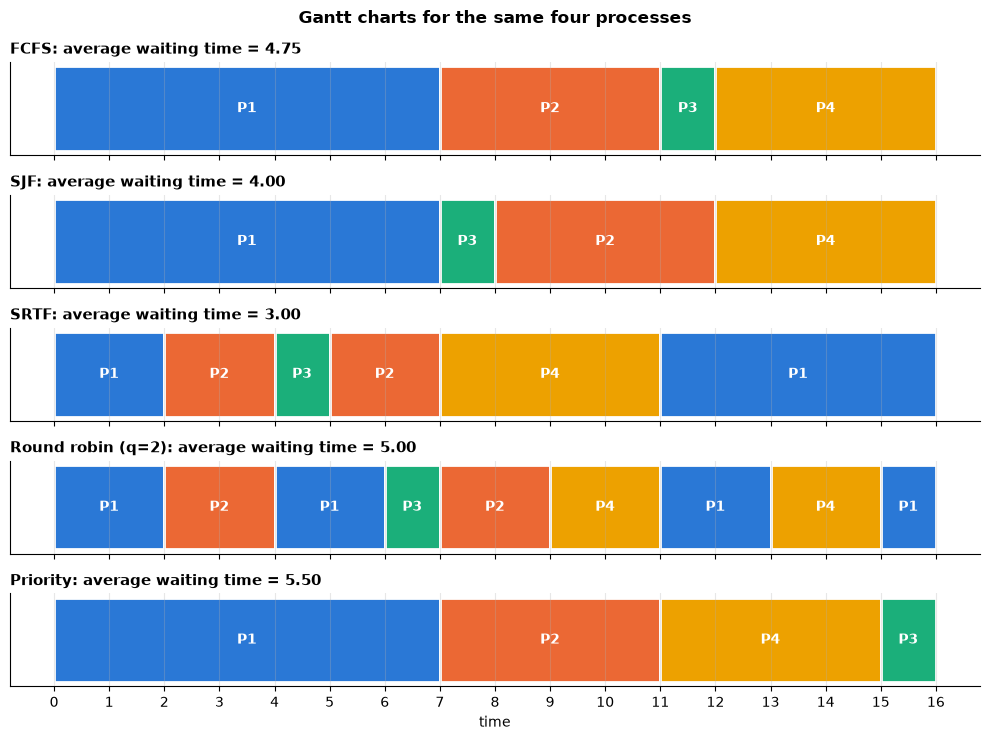

In [12]:
colors = {p.name: PALETTE[i] for i, p in enumerate(procs)}
fig, axes = plt.subplots(len(timelines), 1, figsize=(10, 7.5), sharex=True)
for ax, (name, tl) in zip(axes, timelines.items()):
    for proc, start, end in tl:
        ax.broken_barh([(start, end - start)], (0, 1), facecolors=colors[proc], edgecolor="white", linewidth=2)
        ax.text((start + end) / 2, 0.5, proc, ha="center", va="center", color="white", fontweight="bold")
    avg = metrics(procs, tl)["waiting"].mean()
    ax.set_title(f"{name}: average waiting time = {avg:.2f}", loc="left", fontsize=11)
    ax.set_yticks([]); ax.grid(axis="y", visible=False)
axes[-1].set_xticks(range(0, 17)); axes[-1].set_xlabel("time")
fig.suptitle("Gantt charts for the same four processes", fontweight="bold")
plt.tight_layout(); plt.show()

**What just happened?** The same workload gives very different waiting times:

| Algorithm | Average waiting time |
|---|---|
| FCFS | 4.75 |
| SJF | 4.00 |
| SRTF | 3.00 |
| Round robin (q = 2) | 5.00 |
| Priority | 5.50 |

- **SRTF** has the lowest average waiting time; it is provably optimal for that metric (and SJF is optimal among non-preemptive schedules when all jobs are available at once). The catch: the OS doesn't know burst lengths in advance, so real schedulers *estimate* them from past bursts (exponential averaging).
- **Round robin** has worse average waiting here but good **response time**: everyone gets the CPU soon, which is why interactive systems use time slices.
- **Priority** can **starve** low-priority jobs (P3 waits the longest). The standard fix is **aging**: slowly raise the priority of jobs that have waited a long time.

Let's check the implementation against the classic textbook example (Silberschatz: P1 = 24, P2 = 3, P3 = 3, all arriving at 0) and against brute force: for jobs that all arrive at time 0, SJF must equal the best of *all* possible orders.

In [13]:
book = [Proc("P1", 0, 24), Proc("P2", 0, 3), Proc("P3", 0, 3)]
avg_wait = lambda ps, tl: metrics(ps, tl)["waiting"].mean()
assert avg_wait(book, fcfs(book)) == 17                         # textbook: (0 + 24 + 27) / 3
assert avg_wait(book, sjf(book)) == 3                           # textbook: (6 + 0 + 3) / 3
assert round(avg_wait(book, round_robin(book, 4)), 2) == 5.67   # textbook: 17 / 3
print("textbook values reproduced: FCFS 17, SJF 3, RR(q=4) 5.67")

rng = random.Random(0)
for trial in range(30):                                         # brute-force optimality check
    jobs = [Proc(f"J{i}", 0, rng.randint(1, 9)) for i in range(5)]
    best = min(avg_wait(jobs, [(p.name, s, s + p.burst) for p, s in
                               zip(order, itertools.accumulate([0] + [q.burst for q in order]))])
               for order in itertools.permutations(jobs))
    assert abs(avg_wait(jobs, sjf(jobs)) - best) < 1e-9
print("SJF matched the best of all 120 orders on 30 random job sets")

textbook values reproduced: FCFS 17, SJF 3, RR(q=4) 5.67


SJF matched the best of all 120 orders on 30 random job sets


| Algorithm | Preemptive | Minimises avg wait? | Starvation possible? | Notes |
|---|---|---|---|---|
| FCFS | no | no | no | simple; **convoy effect** (short jobs stuck behind a long one) |
| SJF | no | yes, among non-preemptive (all jobs present) | yes (long jobs) | needs burst estimates |
| SRTF | yes | yes (optimal) | yes (long jobs) | more context switches |
| Round robin | yes | no | no | small `q` = more switches; large `q` = behaves like FCFS |
| Priority | either | no | yes | fix with aging |

**Complexity:** picking the next job by scanning the ready list is O(n) per decision; real schedulers use a heap or tree to make it O(log n). Linux's CFS scheduler kept runnable tasks in a red-black tree ordered by "virtual runtime"; since kernel 6.6 the default is **EEVDF** (Earliest Eligible Virtual Deadline First), which also targets fairness plus latency.

> ⚠️ **Common mistake:** computing waiting time as "start time - arrival" for preemptive algorithms. That's *response* time. Waiting time counts *every* period in the ready queue, so use turnaround - burst.

## 5. Synchronisation

**In plain English:** when two workers change the same data at the same time things break, so we use locks and counters to make them take turns.

When threads share data, the order in which their instructions interleave matters. A **race condition** is a bug whose outcome depends on that timing. The code that touches shared data is the **critical section**; a correct solution must give:

1. **Mutual exclusion**: at most one thread inside the critical section at a time,
2. **Progress**: if nobody is inside, a waiting thread can enter,
3. **Bounded waiting**: no thread waits forever.

`counter += 1` is really three steps: *read* counter, *add* 1, *write* back. If two threads both read 5, both write 6: one update is lost. Real races are rare and random (which is what makes them nasty), so we insert `time.sleep(0)` between read and write to force a switch at the worst moment.

In [14]:
counter = 0
def unsafe_increment(times):
    global counter
    for _ in range(times):
        current = counter            # 1. read the shared value
        time.sleep(0)                # (force a thread switch right here to expose the race)
        counter = current + 1        # 2. write it back: may overwrite someone else's update

lock = threading.Lock()              # a mutex
def safe_increment(times):
    global counter
    for _ in range(times):
        with lock:                   # acquire ... release, even if an exception happens
            current = counter
            time.sleep(0)
            counter = current + 1

for fn in (unsafe_increment, safe_increment):
    counter = 0
    threads = [threading.Thread(target=fn, args=(1000,)) for _ in range(4)]
    for t in threads: t.start()
    for t in threads: t.join()
    print(f"{fn.__name__:<17} expected 4000, got {counter}")
assert counter == 4000                # the locked version is always exact

unsafe_increment  expected 4000, got 1016


safe_increment    expected 4000, got 4000


**What just happened?** Without the lock most increments were lost; with it, the result is exactly 4000 every time.

- A **mutex** (mutual-exclusion lock) has two operations, `acquire` (lock) and `release` (unlock), and only the thread that holds it should release it. `threading.Lock` is a mutex; `threading.RLock` can be re-acquired by the thread that already holds it.
- A **semaphore** (Dijkstra, 1965) is an integer counter with two atomic operations: **`wait` / P / down** (if the counter is 0, block; otherwise decrement) and **`signal` / V / up** (increment, waking a waiter). A **binary semaphore** (0/1) works like a lock; a **counting semaphore** with value `k` lets up to `k` threads in at once.

Typical AI use of a counting semaphore: "allow at most 3 concurrent requests to the GPU / to the LLM API".

In [15]:
gpu_slots = threading.Semaphore(3)            # at most 3 jobs may hold a "GPU slot"
active, max_active, stats_lock = 0, 0, threading.Lock()

def inference_job(i):
    global active, max_active
    with gpu_slots:                           # wait (P) ... signal (V)
        with stats_lock:
            active += 1
            max_active = max(max_active, active)
        time.sleep(0.05)                      # pretend to run the model
        with stats_lock:
            active -= 1

jobs = [threading.Thread(target=inference_job, args=(i,)) for i in range(8)]
t0 = time.perf_counter()
for j in jobs: j.start()
for j in jobs: j.join()
print(f"8 jobs, 3 slots: max running at once = {max_active}, total time {time.perf_counter() - t0:.2f} s")
assert max_active <= 3

8 jobs, 3 slots: max running at once = 3, total time 0.15 s


**What just happened?** Eight jobs arrived, but never more than three ran together; they finished in about three "waves" of 0.05 s.

### The producer-consumer (bounded-buffer) problem

**Producers** put items in a buffer of fixed capacity, **consumers** take them out (think: data-loading threads producing batches, a training loop consuming them; or web requests queued for a batching inference worker). Rules: a producer must wait when the buffer is full, a consumer must wait when it's empty, and the buffer itself must not be corrupted.

The classic solution uses **three** synchronisation objects:

| Object | Initial value | Meaning |
|---|---|---|
| `empty_slots` (semaphore) | capacity | how many free slots remain |
| `full_slots` (semaphore) | 0 | how many items are ready |
| `mutex` (lock) | unlocked | protects the deque itself |

items consumed: 20 | all unique: True | max items ever in buffer: 3 (capacity 3)


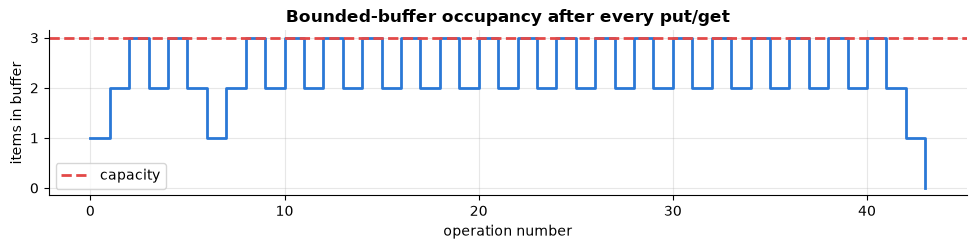

In [16]:
class BoundedBuffer:
    """Bounded buffer built from two semaphores and a mutex (the textbook solution)."""
    def __init__(self, capacity):
        self.items, self.capacity = deque(), capacity
        self.mutex = threading.Lock()
        self.empty_slots = threading.Semaphore(capacity)   # free slots
        self.full_slots = threading.Semaphore(0)           # filled slots
        self.history = []                                  # occupancy after each operation

    def put(self, item):
        self.empty_slots.acquire()              # wait for a free slot (blocks when full)
        with self.mutex:                        # critical section: modify the deque
            self.items.append(item)
            self.history.append(len(self.items))
        self.full_slots.release()               # announce: one more item available

    def get(self):
        self.full_slots.acquire()               # wait for an item (blocks when empty)
        with self.mutex:
            item = self.items.popleft()
            self.history.append(len(self.items))
        self.empty_slots.release()              # announce: one more free slot
        return item

buf, consumed, consumed_lock = BoundedBuffer(capacity=3), [], threading.Lock()

def producer(pid):
    rng = random.Random(pid)
    for k in range(10):
        time.sleep(rng.uniform(0, 0.004))       # producing is fast
        buf.put(f"batch-{pid}-{k}")
    buf.put(None)                               # sentinel: "I'm done"

def consumer():
    rng = random.Random(99)
    while (item := buf.get()) is not None:
        time.sleep(rng.uniform(0.002, 0.008))   # consuming is slower: the buffer fills up
        with consumed_lock:
            consumed.append(item)

workers = [threading.Thread(target=producer, args=(p,)) for p in (1, 2)] + \
          [threading.Thread(target=consumer) for _ in range(2)]
for w in workers: w.start()
for w in workers: w.join()
print("items consumed:", len(consumed), "| all unique:", len(set(consumed)) == 20,
      "| max items ever in buffer:", max(buf.history), "(capacity 3)")
assert len(consumed) == 20 and len(set(consumed)) == 20 and max(buf.history) <= 3

plt.figure(figsize=(10, 2.6))
plt.step(range(len(buf.history)), buf.history, where="post", color=PALETTE[0])
plt.axhline(3, ls="--", color=PALETTE[7], label="capacity")
plt.title("Bounded-buffer occupancy after every put/get"); plt.xlabel("operation number")
plt.ylabel("items in buffer"); plt.legend(); plt.tight_layout(); plt.show()

**What just happened?** All 20 items were consumed exactly once, and the buffer never held more than 3 items: producers blocked on `empty_slots` whenever it was full. (Each sentinel `None` is received by one consumer, which then stops.)

In practice you don't build this yourself: `queue.Queue(maxsize=3)` gives you exactly this behaviour (`put` blocks when full, `get` blocks when empty), and `asyncio.Queue` is the async equivalent.

> ⚠️ **Common mistake:** acquiring the mutex *before* `empty_slots` in `put`. A producer could then hold the mutex while sleeping on a full buffer, and no consumer could ever take the mutex to make room: **deadlock**. Order matters.

### The dining philosophers problem

Five philosophers sit round a table with **one fork between each pair**. To eat, a philosopher needs **both** neighbouring forks. If everybody picks up their *left* fork at the same moment, everybody waits forever for their right fork. We simulate that with locks (and a timeout so the notebook doesn't hang), then apply the classic fix: **resource ordering** (always pick up the lower-numbered fork first).

In [17]:
def dine(n=5, ordered=False, meals=3, timeout=1.0):
    forks = [threading.Lock() for _ in range(n)]
    eaten, waiting_for = [0] * n, {}
    all_stuck = threading.Barrier(n)            # lets the stuck ones report before anyone backs off
    def philosopher(i):
        left, right = i, (i + 1) % n
        first, second = (min(left, right), max(left, right)) if ordered else (left, right)
        for _ in range(meals):
            if not forks[first].acquire(timeout=timeout):
                waiting_for[i] = first; return
            time.sleep(0.05)                                 # ...thinks while holding one fork
            if not forks[second].acquire(timeout=timeout):   # stuck: nobody will ever release it
                waiting_for[i] = second
                try:
                    all_stuck.wait(timeout=2)                # wait until every stuck one has noticed
                except threading.BrokenBarrierError:
                    pass
                forks[first].release(); return
            eaten[i] += 1; time.sleep(0.01)                  # eat
            forks[second].release(); forks[first].release()
    ts = [threading.Thread(target=philosopher, args=(i,)) for i in range(n)]
    for t in ts: t.start()
    for t in ts: t.join()
    return eaten, waiting_for

eaten, waits = dine(ordered=False)
print("naive (everyone takes LEFT fork first): meals eaten =", eaten)
print("  philosopher -> fork it was waiting for:", waits)
eaten2, waits2 = dine(ordered=True)
print("resource ordering (lower fork first):  meals eaten =", eaten2, "| stuck:", waits2)
assert sum(eaten) == 0 and len(waits) == 5 and eaten2 == [3] * 5

naive (everyone takes LEFT fork first): meals eaten = [0, 0, 0, 0, 0]
  philosopher -> fork it was waiting for: {0: 1, 1: 2, 4: 0, 3: 4, 2: 3}


resource ordering (lower fork first):  meals eaten = [3, 3, 3, 3, 3] | stuck: {}


**What just happened?** In the naive version every philosopher held one fork and waited for the next: nobody ever ate. That is a **deadlock**. Drawing who waits for whom (a **wait-for graph**) makes the problem visible: a **cycle**.

cycle found: P0 -> P1 -> P2 -> P3 -> P4 -> P0


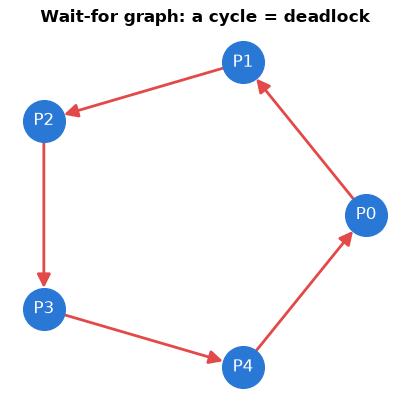

In [18]:
G = nx.DiGraph()
G.add_nodes_from(f"P{i}" for i in range(5))      # fixed order -> a tidy circle
for i, fork in waits.items():
    holder = fork                       # fork k is philosopher k's LEFT fork, so P_k holds it
    G.add_edge(f"P{i}", f"P{holder}")
cycle = nx.find_cycle(G)
print("cycle found:", " -> ".join(u for u, v in cycle), "->", cycle[0][0])

plt.figure(figsize=(4.2, 4.2))
nx.draw_networkx(G, nx.circular_layout(G), node_color=PALETTE[0], font_color="white",
                 node_size=900, arrowsize=20, edge_color=PALETTE[7], width=2)
plt.title("Wait-for graph: a cycle = deadlock"); plt.axis("off"); plt.tight_layout(); plt.show()

### Deadlock: the four Coffman conditions

A **deadlock** is a set of processes each waiting for a resource held by another process in the set. It can occur **only if all four** of these hold at once (Coffman et al., 1971):

| Condition | Meaning | How to break it (prevention) |
|---|---|---|
| **Mutual exclusion** | a resource can be held by one process at a time | make resources shareable (read-only data, lock-free structures) |
| **Hold and wait** | a process holds some resources while waiting for more | request everything at once, or release before asking again |
| **No preemption** | resources can't be taken away forcibly | allow preemption (e.g. `acquire(timeout=...)`, then back off) |
| **Circular wait** | a cycle of processes, each waiting for the next | impose a **global order** on resources (what fixed the philosophers) |

Four ways to handle deadlock: **prevention** (break a condition by design), **avoidance** (only grant requests that keep the system *safe*: the banker's algorithm), **detection and recovery** (find cycles, kill or roll back a victim; databases do this), or **ignore it** (the "ostrich algorithm" most general-purpose OSes use for application locks).

### The banker's algorithm (Dijkstra)

Each process declares the **maximum** it may ever need of each resource type. A state is **safe** if there exists some order (a **safe sequence**) in which every process can get its remaining **Need = Max - Allocation**, finish, and release everything. The banker grants a request only if the state after granting is still safe. Unsafe does not mean deadlocked yet; it means deadlock *can no longer be ruled out*.

Textbook example (Silberschatz): resources A, B, C with 10, 5, 7 instances; Available = (3, 3, 2).

| | Allocation (A B C) | Max (A B C) | Need (A B C) |
|---|---|---|---|
| P0 | 0 1 0 | 7 5 3 | 7 4 3 |
| P1 | 2 0 0 | 3 2 2 | 1 2 2 |
| P2 | 3 0 2 | 9 0 2 | 6 0 0 |
| P3 | 2 1 1 | 2 2 2 | 0 1 1 |
| P4 | 0 0 2 | 4 3 3 | 4 3 1 |

By hand: Work = (3,3,2). P0 needs (7,4,3): no. P1 needs (1,2,2): yes, finishes, Work = (5,3,2). P2 (6,0,0): no. P3 (0,1,1): yes, Work = (7,4,3). P4 (4,3,1): yes, Work = (7,4,5). Second pass: P0 yes, Work = (7,5,5); P2 yes, Work = (10,5,7). So the state is safe with sequence **P1 -> P3 -> P4 -> P0 -> P2** (the textbook lists P1, P3, P4, P2, P0; several safe sequences can exist).

In [19]:
def need_matrix(max_demand, allocation):
    return [[mx - al for mx, al in zip(mrow, arow)] for mrow, arow in zip(max_demand, allocation)]

def is_safe(available, max_demand, allocation):
    """Banker's safety algorithm. Returns (safe?, a safe sequence)."""
    need = need_matrix(max_demand, allocation)
    work = list(available)                            # resources free right now
    finish = [False] * len(allocation)
    sequence, progress = [], True
    while progress:                                   # keep scanning while someone can finish
        progress = False
        for i in range(len(allocation)):
            if not finish[i] and all(nd <= w for nd, w in zip(need[i], work)):
                work = [w + a for w, a in zip(work, allocation[i])]   # P_i runs to the end, releases all
                finish[i] = True
                sequence.append(f"P{i}")
                progress = True
    return all(finish), sequence

def request(pid, req, available, max_demand, allocation):
    """Banker's resource-request algorithm: grant only if the resulting state is safe."""
    need = need_matrix(max_demand, allocation)[pid]
    if any(r > nd for r, nd in zip(req, need)):
        return False, "error: request exceeds the declared maximum", available, allocation
    if any(r > av for r, av in zip(req, available)):
        return False, "must wait: not enough resources available right now", available, allocation
    new_available = [av - r for av, r in zip(available, req)]           # pretend to grant ...
    new_allocation = [row[:] for row in allocation]
    new_allocation[pid] = [a + r for a, r in zip(allocation[pid], req)]
    safe, seq = is_safe(new_available, max_demand, new_allocation)      # ... and check safety
    if safe:
        return True, f"granted (safe sequence {' -> '.join(seq)})", new_available, new_allocation
    return False, "denied: granting it would leave the system in an UNSAFE state", available, allocation

In [20]:
available  = [3, 3, 2]
max_demand = [[7, 5, 3], [3, 2, 2], [9, 0, 2], [2, 2, 2], [4, 3, 3]]
allocation = [[0, 1, 0], [2, 0, 0], [3, 0, 2], [2, 1, 1], [0, 0, 2]]
print(pd.DataFrame(need_matrix(max_demand, allocation), columns=list("ABC"),
                   index=[f"P{i}" for i in range(5)]).T.rename_axis("Need").to_string(), "\n")

safe, seq = is_safe(available, max_demand, allocation)
print("initial state safe?", safe, "| safe sequence:", " -> ".join(seq))

ok, msg, available, allocation = request(1, [1, 0, 2], available, max_demand, allocation)
print("P1 requests (1,0,2):", msg, "| Available now", available)
for pid, req in [(4, [3, 3, 0]), (0, [0, 2, 0])]:
    ok, msg, _, _ = request(pid, req, available, max_demand, allocation)
    print(f"P{pid} requests {tuple(req)}:", msg)

      P0  P1  P2  P3  P4
Need                    
A      7   1   6   0   4
B      4   2   0   1   3
C      3   2   0   1   1 

initial state safe? True | safe sequence: P1 -> P3 -> P4 -> P0 -> P2
P1 requests (1,0,2): granted (safe sequence P1 -> P3 -> P4 -> P0 -> P2) | Available now [2, 3, 0]
P4 requests (3, 3, 0): must wait: not enough resources available right now
P0 requests (0, 2, 0): denied: granting it would leave the system in an UNSAFE state


These are exactly the textbook outcomes: P1's request is granted, P4's must wait (only (2,3,0) is free), and P0's would leave an unsafe state so it is refused even though the resources physically exist.

Brute-force check: a state is safe exactly when *some* permutation of the processes can finish one by one. We compare that against `is_safe` on random states.

In [21]:
def safe_by_brute_force(available, max_demand, allocation):
    need = need_matrix(max_demand, allocation)
    for order in itertools.permutations(range(len(allocation))):
        work, ok = list(available), True
        for i in order:
            if any(nd > w for nd, w in zip(need[i], work)):
                ok = False; break
            work = [w + a for w, a in zip(work, allocation[i])]
        if ok:
            return True
    return False

rng = random.Random(1)
n_safe = 0
for _ in range(400):
    alloc = [[rng.randint(0, 3) for _ in range(3)] for _ in range(4)]
    mx = [[a + rng.randint(0, 4) for a in row] for row in alloc]
    av = [rng.randint(0, 4) for _ in range(3)]
    fast = is_safe(av, mx, alloc)[0]
    assert fast == safe_by_brute_force(av, mx, alloc)
    n_safe += fast
print(f"banker's algorithm agreed with brute force on 400 random states ({n_safe} safe, {400 - n_safe} unsafe)")

banker's algorithm agreed with brute force on 400 random states (158 safe, 242 unsafe)


**Complexity:** the safety algorithm is O(m · n²) for n processes and m resource types (up to n passes, each scanning n processes and comparing m numbers), versus O(n! · n · m) for brute force. It's rarely used in general-purpose OSes (processes don't declare maxima), but the idea shows up in admission control, e.g. a GPU cluster scheduler that only starts a job if its declared memory still fits.

> 🎓 **Interview tip:** "How do you avoid deadlocks in your code?" A strong answer: acquire locks in a consistent global order, hold them briefly, never call unknown code (callbacks, I/O) while holding a lock, use timeouts, and prefer higher-level tools (queues, `concurrent.futures`, `asyncio`) over hand-rolled locking.

## 6. Memory management

**In plain English:** every program gets its own pretend memory; the OS maps it onto real RAM in small pages and decides what to throw out when RAM is full.

### Virtual memory and paging

Every process sees its own private, contiguous **virtual address space**, as if it had the whole machine's memory. The hardware **MMU** (memory management unit) translates each virtual address to a **physical** address in RAM, using tables maintained by the kernel. Benefits: **isolation** (a process can't even name another's memory), the illusion of more memory than RAM (rarely used pages can be swapped to disk), **sharing** (one copy of `libc` or of a read-only model file mapped into many processes) and **lazy loading** (pages are only brought in when touched).

**Paging** splits virtual memory into fixed-size **pages** and physical memory into equal-size **frames** (typically 4 KiB; "huge pages" of 2 MiB or 1 GiB also exist). A **page table** maps page number → frame number plus flag bits (present, writable, user, dirty, accessed).

A virtual address splits into **page number** and **offset**:

```
virtual address 0x3A7F  with 4 KiB pages (offset = low 12 bits)
   = page 0x3, offset 0xA7F
page table: page 3 -> frame 7
physical address = 7 * 4096 + 0xA7F = 0x7A7F
```

If the page isn't present, the MMU raises a **page fault**; the kernel finds a free frame (evicting a page if needed), loads the data, fixes the page table and restarts the instruction. On x86-64, translation uses a **4-level** page table for 48-bit virtual addresses (5-level for 57-bit on newer CPUs), so each page fits in one small table per level rather than one gigantic array.

In [22]:
PAGE_SIZE = 4096
page_table = {0: 2, 1: 5, 3: 7}                 # page -> frame (pages 2, 4, ... are not present)

def translate(vaddr):
    page, offset = divmod(vaddr, PAGE_SIZE)      # the same as (vaddr >> 12, vaddr & 0xFFF)
    if page not in page_table:
        return f"0x{vaddr:05X} -> page {page} not present: PAGE FAULT"
    paddr = page_table[page] * PAGE_SIZE + offset
    return f"0x{vaddr:05X} -> page {page}, offset 0x{offset:03X} -> frame {page_table[page]} -> 0x{paddr:05X}"

for va in [0x3A7F, 0x0010, 0x1FFF, 0x2000]:
    print(translate(va))
print("this machine's page size:", os.sysconf("SC_PAGE_SIZE"), "bytes")

0x03A7F -> page 3, offset 0xA7F -> frame 7 -> 0x07A7F
0x00010 -> page 0, offset 0x010 -> frame 2 -> 0x02010
0x01FFF -> page 1, offset 0xFFF -> frame 5 -> 0x05FFF
0x02000 -> page 2 not present: PAGE FAULT
this machine's page size: 4096 bytes


### The TLB

Walking a 4-level page table on every memory access would multiply memory traffic. The **TLB** (translation lookaside buffer) is a small, very fast cache of recent page → frame translations inside the CPU (tens to a few thousand entries). With TLB hit ratio `h`, TLB lookup time `t_tlb` and memory access time `t_mem`, the textbook (single-level page table) **effective access time** is:

`EAT = h * (t_tlb + t_mem) + (1 - h) * (t_tlb + 2 * t_mem)`

For `t_tlb` = 20 ns, `t_mem` = 100 ns: h = 0.80 gives 0.8 * 120 + 0.2 * 220 = **140 ns**; h = 0.98 gives **122 ns**.

The TLB is why **memory access patterns matter**: walking an array in order touches each page thousands of times in a row, while random jumps miss constantly. We simulate a 16-entry LRU TLB.

In [23]:
def eat(h, t_tlb=20, t_mem=100):
    return h * (t_tlb + t_mem) + (1 - h) * (t_tlb + 2 * t_mem)
print("EAT at 80% hits:", round(eat(0.80), 1), "ns | at 98% hits:", round(eat(0.98), 1), "ns")

def tlb_hit_rate(addresses, entries=16):
    tlb, hits = [], 0                              # list ordered from least to most recently used
    for a in addresses:
        page = a // PAGE_SIZE
        if page in tlb:
            hits += 1; tlb.remove(page)
        elif len(tlb) == entries:
            tlb.pop(0)                             # evict least recently used translation
        tlb.append(page)
    return hits / len(addresses)

n_elems = 64 * PAGE_SIZE // 8                      # 64 pages worth of 8-byte floats
sequential = [i * 8 for i in range(n_elems)]       # a[0], a[1], a[2], ...
rng = np.random.default_rng(0)
scattered = (rng.integers(0, 1024, n_elems) * PAGE_SIZE).tolist()   # jump between 1024 pages
print(f"sequential scan hit rate: {tlb_hit_rate(sequential):.2%}")
print(f"random page jumps hit rate: {tlb_hit_rate(scattered):.2%}")

EAT at 80% hits: 140.0 ns | at 98% hits: 122.0 ns
sequential scan hit rate: 99.80%


random page jumps hit rate: 1.63%


**What just happened?** The sequential scan misses only once per page (1 miss per 512 accesses, a 99.80% hit rate). Random jumps across 1024 pages with only 16 cached translations almost always miss. This (together with CPU caches) is one reason contiguous NumPy/PyTorch tensors are fast and why `.contiguous()` matters.

### Page replacement: FIFO, LRU and Optimal

When a page fault occurs and all frames are full, the OS must evict a **victim** page:

| Algorithm | Evicts | Comment |
|---|---|---|
| **FIFO** | the page loaded longest ago | simple; can suffer **Belady's anomaly** |
| **LRU** (least recently used) | the page used longest ago | good approximation of OPT; exact LRU is expensive in hardware |
| **OPT / MIN** (Belady's optimal) | the page used farthest in the future | provably fewest faults, but needs the future: a benchmark only |

Real kernels approximate LRU cheaply with a "referenced" bit: the **clock / second-chance** algorithm (Practice problem 6), and in Linux active/inactive page lists (optionally the multi-generational LRU, MGLRU, merged in kernel 6.1).

In [24]:
def simulate(refs, n_frames, policy):
    """Generic demand-paging simulator. `policy` picks the victim page when all frames are full."""
    slots, loaded_at, last_used = [], {}, {}         # slots[i] = page held by physical frame i
    faults, trace = 0, []
    for i, page in enumerate(refs):
        fault = page not in slots
        if fault:
            faults += 1
            if len(slots) < n_frames:                 # a free frame exists
                slots.append(page)
            else:                                     # evict someone
                victim = policy(slots, i, refs, loaded_at, last_used)
                slots[slots.index(victim)] = page
            loaded_at[page] = i
        last_used[page] = i
        row = {"ref": page}
        row.update({f"frame {k}": (slots[k] if k < len(slots) else "") for k in range(n_frames)})
        row["fault"] = "F" if fault else ""
        trace.append(row)
    return faults, trace

def fifo_victim(slots, i, refs, loaded_at, last_used):
    return min(slots, key=lambda p: loaded_at[p])     # loaded longest ago

def lru_victim(slots, i, refs, loaded_at, last_used):
    return min(slots, key=lambda p: last_used[p])     # used longest ago

def opt_victim(slots, i, refs, loaded_at, last_used):
    def next_use(p):                                  # when will p be needed again?
        for j in range(i + 1, len(refs)):
            if refs[j] == p:
                return j
        return float("inf")                           # never again: perfect victim
    return max(slots, key=next_use)                   # needed farthest in the future

def fifo(refs, n): return simulate(refs, n, fifo_victim)
def lru(refs, n):  return simulate(refs, n, lru_victim)
def opt(refs, n):  return simulate(refs, n, opt_victim)

In [25]:
refs = [7, 0, 1, 2, 0, 3, 0, 4, 2, 3, 0, 3, 2, 1, 2, 0, 1, 7, 0, 1]   # the classic textbook string
for name, alg in [("FIFO", fifo), ("LRU", lru), ("OPT", opt)]:
    print(f"{name:<4} with 3 frames: {alg(refs, 3)[0]} page faults")
faults, trace = fifo(refs, 3)
print("\nFIFO trace (F = page fault):")
print(pd.DataFrame(trace).T.to_string(header=False))

FIFO with 3 frames: 15 page faults
LRU  with 3 frames: 12 page faults
OPT  with 3 frames: 9 page faults

FIFO trace (F = page fault):
ref      7  0  1  2  0  3  0  4  2  3  0  3  2  1  2  0  1  7  0  1
frame 0  7  7  7  2  2  2  2  4  4  4  0  0  0  0  0  0  0  7  7  7
frame 1     0  0  0  0  3  3  3  2  2  2  2  2  1  1  1  1  1  0  0
frame 2        1  1  1  1  0  0  0  3  3  3  3  3  2  2  2  2  2  1
fault    F  F  F  F     F  F  F  F  F  F        F  F        F  F  F


**What just happened?** On the textbook reference string with 3 frames, FIFO causes **15** faults, LRU **12** and OPT **9**, exactly the values in Silberschatz. Read the trace column by column: e.g. at the 4th reference (page 2) all frames are full, and FIFO evicts 7 because it was loaded first.

### Belady's anomaly

Intuition says more memory → fewer page faults. For FIFO this can be **false**. On the string `1 2 3 4 1 2 5 1 2 3 4 5`, FIFO makes 9 faults with 3 frames but **10** with 4 frames. LRU and OPT are **stack algorithms** (the pages held with `k` frames are always a subset of those held with `k+1`), so they can never show the anomaly.

frames   1   2   3   4  5  6  7
FIFO    12  12   9  10  5  5  5
LRU     12  12  10   8  5  5  5
OPT     12   9   7   6  5  5  5


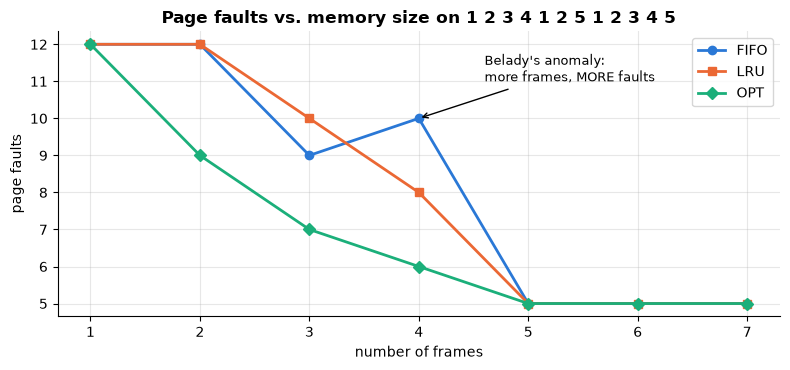

In [26]:
belady = [1, 2, 3, 4, 1, 2, 5, 1, 2, 3, 4, 5]
frames = range(1, 8)
curves = {name: [alg(belady, k)[0] for k in frames] for name, alg in [("FIFO", fifo), ("LRU", lru), ("OPT", opt)]}
print(pd.DataFrame(curves, index=pd.Index(frames, name="frames")).T)

plt.figure(figsize=(8, 3.8))
for (name, ys), marker in zip(curves.items(), "osD"):
    plt.plot(frames, ys, marker=marker, label=name)
plt.annotate("Belady's anomaly:\nmore frames, MORE faults", xy=(4, curves["FIFO"][3]), xytext=(4.6, 11),
             arrowprops=dict(arrowstyle="->"), fontsize=9)
plt.xlabel("number of frames"); plt.ylabel("page faults"); plt.legend()
plt.title("Page faults vs. memory size on 1 2 3 4 1 2 5 1 2 3 4 5"); plt.tight_layout(); plt.show()

Now we verify correctness: OPT must equal the true minimum found by an exhaustive search over every possible eviction choice, never be beaten by FIFO or LRU, and LRU's fault count must never increase when we add frames.

In [27]:
from functools import lru_cache

def brute_min_faults(refs, n_frames):
    """Try every possible eviction choice (exponential, tiny inputs only)."""
    @lru_cache(maxsize=None)
    def go(i, frames):
        if i == len(refs):
            return 0
        p = refs[i]
        if p in frames:
            return go(i + 1, frames)
        if len(frames) < n_frames:
            return 1 + go(i + 1, frames | {p})
        return 1 + min(go(i + 1, (frames - {v}) | {p}) for v in frames)
    return go(0, frozenset())

rng = random.Random(7)
for _ in range(200):
    s = [rng.randint(0, 5) for _ in range(rng.randint(5, 14))]
    k = rng.randint(1, 4)
    best = opt(s, k)[0]
    assert best == brute_min_faults(tuple(s), k)
    assert best <= lru(s, k)[0] and best <= fifo(s, k)[0]
    assert all(lru(s, j)[0] >= lru(s, j + 1)[0] for j in range(1, 6))
print("200 random strings: OPT == exhaustive optimum, OPT <= LRU and FIFO, LRU never shows Belady's anomaly")

200 random strings: OPT == exhaustive optimum, OPT <= LRU and FIFO, LRU never shows Belady's anomaly


**Complexity:** with a hash map, FIFO and LRU cost O(1) per reference (LRU uses a hash map plus a doubly linked list, which is how `functools.lru_cache` works); our simple list versions are O(frames). OPT as written is O(frames · length) per fault because it scans the future.

**Thrashing**: if a process's *working set* (the pages it actively uses) doesn't fit in RAM, it spends more time page-faulting than computing. On a laptop this feels like a frozen machine while the disk light is on. In ML it happens when a dataset or model slightly exceeds RAM and the system starts swapping.

### Stack vs. heap

| | Stack | Heap |
|---|---|---|
| holds | function call frames: local variables, return addresses | dynamically allocated objects whose lifetime isn't tied to one call |
| managed by | automatic: push on call, pop on return | an allocator (`malloc`/`free`; in Python, reference counting + garbage collector) |
| speed | very fast (move a pointer) | slower (find a free block) |
| size | small and fixed per thread (often 8 MiB on Linux) | large, grows as needed |
| typical error | **stack overflow** (runaway recursion) | **memory leak**, fragmentation, use-after-free (in C/C++) |

In CPython, every object (ints, lists, tensors' Python wrappers) lives on the heap; call frames are tracked on a stack, and Python caps recursion depth to avoid overflowing the C stack.

In [28]:
soft, hard = resource.getrlimit(resource.RLIMIT_STACK)
print("main-thread stack limit:", "unlimited" if soft == resource.RLIM_INFINITY else f"{soft // 2**20} MiB",
      "| Python recursion limit:", sys.getrecursionlimit())

def depth(n):
    return 0 if n == 0 else 1 + depth(n - 1)
try:
    depth(100_000)
except RecursionError as e:
    print("RecursionError caught:", e)
print("depth(500) works fine:", depth(500))

main-thread stack limit: 8 MiB | Python recursion limit: 1000
RecursionError caught: maximum recursion depth exceeded
depth(500) works fine: 500


### Memory leaks in Python

Python frees an object automatically when nothing refers to it any more. A **leak** in Python therefore means *something still refers to data you no longer need*: a module-level list or dict that only grows, an unbounded cache, a global list of all past requests. In a long-running API server that's a slow death: memory grows until the container is OOM-killed (exit code 137, Section 8).

`tracemalloc` (standard library) measures memory allocated by Python code. We compare a leaky request handler with a fixed one that keeps only a bounded history.

leaky                      memory after 1000 requests: 7.25 MB
bounded (deque maxlen=50)  memory after 1000 requests: 0.36 MB


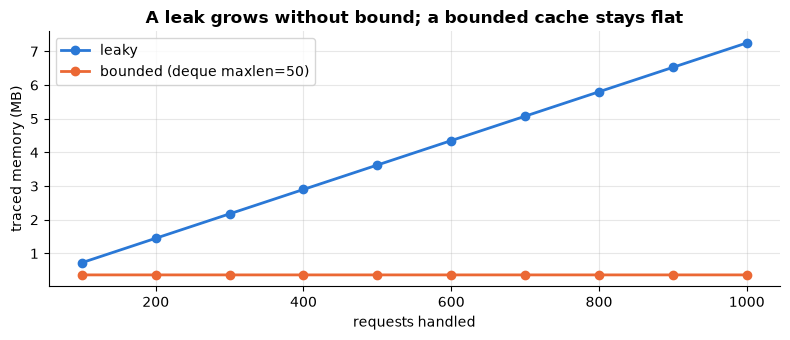

In [29]:
leaky_history = []                                  # module-level list that only grows: a leak
def handle_leaky(payload):
    leaky_history.append(payload * 100)             # keeps every response forever
    return len(payload)

bounded_history = deque(maxlen=50)                  # the fix: keep only the last 50
def handle_bounded(payload):
    bounded_history.append(payload * 100)
    return len(payload)

usage = {}
for name, handler in [("leaky", handle_leaky), ("bounded (deque maxlen=50)", handle_bounded)]:
    tracemalloc.start()
    points = []
    for request_no in range(1, 1001):
        handler(f"user prompt number {request_no:04d} " * 3)   # 72 characters per request
        if request_no % 100 == 0:
            points.append(tracemalloc.get_traced_memory()[0] / 1e6)   # MB currently allocated
    tracemalloc.stop()
    usage[name] = points
    print(f"{name:<26} memory after 1000 requests: {points[-1]:.2f} MB")

plt.figure(figsize=(8, 3.5))
for name, pts in usage.items():
    plt.plot(range(100, 1001, 100), pts, marker="o", label=name)
plt.xlabel("requests handled"); plt.ylabel("traced memory (MB)"); plt.legend()
plt.title("A leak grows without bound; a bounded cache stays flat"); plt.tight_layout(); plt.show()
leaky_history.clear()

**What just happened?** The leaky handler's memory grew linearly with the number of requests (about 7 KB per request: each stored string is 100 copies of a 72-character prompt), while the bounded version levelled off after 50 requests.

> ⚠️ **Common mistake (PyTorch):** `total_loss += loss` inside a training loop keeps the whole autograd graph of every step alive, a GPU memory leak. Use `total_loss += loss.item()` (a plain Python float). Similarly, appending model outputs to a list without `.detach().cpu()` keeps GPU tensors alive.

### Loading big models: `mmap` and safetensors

**`mmap`** maps a file into the process's virtual address space. Nothing is read up front: when the program touches a page, a page fault loads just that 4 KiB from disk (or from the OS **page cache** if it was read recently). Several processes mapping the same read-only file share the same physical pages. That's how you can "open" a multi-GB model instantly and why several workers loading the same weights don't need several copies in RAM.

We save a 64 MB array and compare a full read with a memory-mapped open.

In [30]:
arr = np.random.default_rng(0).standard_normal((4096, 4096), dtype=np.float32)   # 64 MiB "weights"
np.save(WORK / "weights.npy", arr)

t = time.perf_counter(); full = np.load(WORK / "weights.npy");                 t_full = time.perf_counter() - t
t = time.perf_counter(); lazy = np.load(WORK / "weights.npy", mmap_mode="r");  t_map = time.perf_counter() - t
t = time.perf_counter(); row = np.array(lazy[1234]);                           t_row = time.perf_counter() - t
print(f"np.load (reads all 64 MiB):     {t_full * 1000:8.2f} ms")
print(f"np.load(mmap_mode='r'):         {t_map * 1000:8.2f} ms  (nothing read yet)")
print(f"touch one row (16 KiB) via mmap: {t_row * 1000:8.2f} ms")
assert np.array_equal(row, full[1234])
del full, lazy, row

np.load (reads all 64 MiB):       102.04 ms
np.load(mmap_mode='r'):             5.76 ms  (nothing read yet)
touch one row (16 KiB) via mmap:     2.44 ms


**What just happened?** The memory-mapped open returned almost instantly because the kernel only set up page-table entries; touching one row faulted in just the few pages it lives on. (The full read is fast here because the file is still in the page cache from the save; from a cold disk it would be much slower.)

**safetensors** (Hugging Face's format, the default for model weights on the Hub) is designed for exactly this. A file is:

```
[ 8 bytes: N = header length, little-endian u64 ]
[ N bytes: JSON header {"name": {"dtype": "F32", "shape": [..], "data_offsets": [start, end]}, ...} ]
[ raw tensor bytes, back to back ]
```

Because it's just a header plus raw bytes, a loader can `mmap` the file and create tensors that point straight into it (zero-copy), and, unlike pickle-based `.bin`/`.pt` files, **loading it can't execute arbitrary code**. Let's write and read the format from scratch.

In [31]:
DTYPES = {np.dtype("float32"): "F32", np.dtype("float16"): "F16", np.dtype("int64"): "I64"}
NP_OF = {v: k for k, v in DTYPES.items()}

def save_safetensors(tensors, path):
    header, offset, blobs = {}, 0, []
    for name, a in tensors.items():
        a = np.ascontiguousarray(a)
        header[name] = {"dtype": DTYPES[a.dtype], "shape": list(a.shape),
                        "data_offsets": [offset, offset + a.nbytes]}
        blobs.append(a.tobytes()); offset += a.nbytes
    header["__metadata__"] = {"format": "np"}
    hb = json.dumps(header, separators=(",", ":")).encode()
    hb += b" " * (-len(hb) % 8)                         # pad the header to 8-byte alignment
    with open(path, "wb") as f:
        f.write(struct.pack("<Q", len(hb)))             # little-endian unsigned 64-bit length
        f.write(hb)
        for b in blobs:
            f.write(b)

def load_safetensors_mmap(path):
    """Zero-copy load: arrays are views into a memory-mapped file."""
    with open(path, "rb") as f:
        mm = mmap.mmap(f.fileno(), 0, access=mmap.ACCESS_READ)   # the mapping outlives the file object
    n = struct.unpack("<Q", mm[:8])[0]
    header = json.loads(mm[8:8 + n])
    base = 8 + n
    out = {}
    for name, info in header.items():
        if name == "__metadata__":
            continue
        start, end = info["data_offsets"]
        dt = NP_OF[info["dtype"]]
        out[name] = np.frombuffer(mm, dtype=dt, count=(end - start) // dt.itemsize,
                                  offset=base + start).reshape(info["shape"])
    return out, header

model = {"embed.weight": np.arange(12, dtype=np.float32).reshape(3, 4),
         "head.bias": np.ones(4, dtype=np.float16), "step": np.array([1000], dtype=np.int64)}
save_safetensors(model, WORK / "tiny.safetensors")
loaded, header = load_safetensors_mmap(WORK / "tiny.safetensors")
print("header:", json.dumps({k: v for k, v in header.items() if k != "__metadata__"}))
print("embed.weight row 2:", loaded["embed.weight"][2], "| writable?", loaded["embed.weight"].flags.writeable)
assert all(np.array_equal(loaded[k], model[k]) for k in model)

try:                                                     # optional: cross-check with the real library
    from safetensors.numpy import load_file, save_file
    assert all(np.array_equal(load_file(str(WORK / "tiny.safetensors"))[k], model[k]) for k in model)
    save_file(model, str(WORK / "lib.safetensors"))
    assert all(np.array_equal(load_safetensors_mmap(WORK / "lib.safetensors")[0][k], model[k]) for k in model)
    print("safetensors library reads our file, and we read its file: formats match")
except ImportError:
    print("(safetensors library not installed; skipping the optional cross-check)")
del loaded

header: {"embed.weight": {"dtype": "F32", "shape": [3, 4], "data_offsets": [0, 48]}, "head.bias": {"dtype": "F16", "shape": [4], "data_offsets": [48, 56]}, "step": {"dtype": "I64", "shape": [1], "data_offsets": [56, 64]}}
embed.weight row 2: [ 8.  9. 10. 11.] | writable? False
safetensors library reads our file, and we read its file: formats match


**What just happened?** We produced a valid safetensors file with nothing but `struct`, `json` and NumPy, and loaded it as read-only views into a memory map; the official library (if installed) agrees with us in both directions.

What this means for loading big models:
- **RAM needed ≈ parameters × bytes per parameter** (7B parameters in fp16 ≈ 14 GB; in 4-bit ≈ 3.5-4 GB), plus activations and, for LLMs, the KV cache.
- mmap-based loading (safetensors in `transformers`, GGUF in llama.cpp) avoids a second copy in RAM and starts fast; the OS page cache makes the second load faster still.
- On a GPU, weights must still be *copied* to device memory; `device_map="auto"` loads them shard by shard instead of building the whole model in CPU RAM first.
- Never load untrusted pickle files: `torch.load(..., weights_only=True)` (the default since PyTorch 2.6) or safetensors.

## 7. File systems

**In plain English:** a file system turns a disk into named files and folders and decides who may read, change or run each one.

A **file system** organises a disk into files and directories. On Unix-like systems the key structure is the **inode**: a record holding a file's *metadata* (size, owner, permissions, timestamps, number of links) and where its data blocks are. The file's **name is not in the inode**. A directory is just a table mapping names → inode numbers.

```
directory "project/"                inode 1835013                    data blocks
+-------------+---------+          +----------------------+          +-----------+
| notes.txt   | 1835013 | -------> | size 24 B, mode 644  | -------> | "hello..." |
| backup.txt  | 1835013 | ---+     | links: 2, owner, ... |          +-----------+
+-------------+---------+    |     +----------------------+
                             +----> (a hard link: same inode)
```

| Concept | Meaning |
|---|---|
| **absolute path** | starts at the root `/`: `/srv/models/bert` |
| **relative path** | relative to the current working directory: `models/bert`, `../data` |
| `.` / `..` | the current directory / its parent |
| **hard link** | another name for the *same inode*; the data lives until the last link is removed |
| **symbolic (soft) link** | a tiny file containing a *path*; it breaks ("dangles") if the target moves |

In [32]:
proj = WORK / "project"; proj.mkdir()
notes = proj / "notes.txt"; notes.write_text("hello, file systems!\n")
os.link(notes, proj / "backup.txt")                     # hard link: new name, same inode
os.symlink("notes.txt", proj / "shortcut.txt")          # symlink: a file containing the path "notes.txt"

def info(p):
    st = os.lstat(p)                                    # lstat: don't follow symlinks
    return {"name": p.name, "inode": st.st_ino, "links": st.st_nlink, "size": st.st_size,
            "mode": stat.filemode(st.st_mode)}
print(pd.DataFrame([info(proj / n) for n in ["notes.txt", "backup.txt", "shortcut.txt"]]).to_string(index=False))
assert os.lstat(notes).st_ino == os.lstat(proj / "backup.txt").st_ino

notes.unlink()                                          # delete the original name
print("\nafter deleting notes.txt:")
print("  backup.txt still reads:", (proj / "backup.txt").read_text().strip())
print("  shortcut.txt is a symlink:", (proj / "shortcut.txt").is_symlink(),
      "| target exists:", (proj / "shortcut.txt").exists())
print("path tricks:", os.path.normpath("/srv/app/../models/./bert"), "|",
      (proj / "data" / "train.csv").relative_to(WORK), "| suffix:", Path("model.safetensors").suffix)

        name   inode  links  size       mode
   notes.txt 9058740      2    21 -rw-rw-r--
  backup.txt 9058740      2    21 -rw-rw-r--
shortcut.txt 9058744      1     9 lrwxrwxrwx

after deleting notes.txt:
  backup.txt still reads: hello, file systems!
  shortcut.txt is a symlink: True | target exists: False
path tricks: /srv/models/bert | project/data/train.csv | suffix: .safetensors


**What just happened?** `notes.txt` and `backup.txt` share **one inode** (the link count was 2); the symlink has its own inode and its mode starts with `l`. After deleting `notes.txt`, the data survived through the hard link, but the symlink now **dangles** (it still exists, its target doesn't). This is also how Hugging Face's cache works: files under `snapshots/` are symlinks into a `blobs/` folder, so identical files are stored once.

### Permissions: `rwx`, `chmod`, `umask`

Each file has an **owner** (user), a **group**, and three permission triplets for **user / group / others**: **r**ead, **w**rite, e**x**ecute. Written in octal, r = 4, w = 2, x = 1, summed per triplet:

| Octal | Symbolic | Typical use |
|---|---|---|
| 644 | `rw-r--r--` | normal files (owner edits, everyone reads) |
| 600 | `rw-------` | secrets: `.env`, SSH private keys (ssh *refuses* keys readable by others) |
| 755 | `rwxr-xr-x` | scripts, directories |
| 700 | `rwx------` | private directories (`~/.ssh`) |

For a **directory**, r = list names, w = create/delete entries, x = enter/traverse it.

**`umask`** is a per-process mask of permission bits to *remove* from newly created files: new files start from 666 and directories from 777, minus the umask. With umask 022: files 644, dirs 755. With umask 077: files 600, dirs 700.

In [33]:
def mode(p):
    return stat.filemode(p.stat().st_mode)

old = os.umask(0o022)                                    # set a known umask (and remember the old one)
try:
    for mask in (0o022, 0o077):
        os.umask(mask)
        f = WORK / f"file_umask_{mask:03o}.txt"; f.write_text("x")
        d = WORK / f"dir_umask_{mask:03o}"; d.mkdir()
        print(f"umask {mask:03o}: new file {mode(f)}  new dir {mode(d)}")
finally:
    os.umask(old)                                        # always restore the process umask

secret = WORK / ".env"; secret.write_text("OPENAI_API_KEY=sk-fake-demo\n")
os.chmod(secret, 0o600)                                  # chmod 600 .env
print("after chmod 600:", mode(secret))

script = WORK / "hello.sh"; script.write_text("#!/bin/sh\necho 'script ran'\n")
os.chmod(script, 0o644)
try:
    subprocess.run([str(script)], env=SAFE_ENV)
except PermissionError as e:
    print(f"running without x bit -> {type(e).__name__} (errno {e.errno}: {e.strerror})")
os.chmod(script, script.stat().st_mode | stat.S_IXUSR | stat.S_IXGRP | stat.S_IXOTH)   # chmod +x
print("after chmod +x:", mode(script), "->", subprocess.run([str(script)], env=SAFE_ENV,
                                                          capture_output=True, text=True).stdout.strip())
sh("ls -l hello.sh .env")

umask 022: new file -rw-r--r--  new dir drwxr-xr-x
umask 077: new file -rw-------  new dir drwx------
after chmod 600: -rw-------
running without x bit -> PermissionError (errno 13: Permission denied)
after chmod +x: -rwxr-xr-x -> script ran
$ ls -l hello.sh .env
-rw------- 1 learner learner 28 Oct 27 13:49 .env
-rwxr-xr-x 1 learner learner 28 Oct 27 13:49 hello.sh


**What just happened?** The same code created files with different permissions depending only on the umask. `chmod 600` locked the secret file down to its owner, and the script could only be executed after `chmod +x`. (In the `ls -l` output the owner and group names are redacted to `learner`.)

> ⚠️ **Common mistake:** "fixing" permission errors with `chmod -R 777`. That lets every user on the machine (and every compromised service) modify your code and read your secrets. Find which user needs which access and grant only that.

### File descriptors and buffering

When a process opens a file, the kernel returns a **file descriptor (fd)**: a small integer indexing that process's table of open files. Every process starts with **0 = stdin, 1 = stdout, 2 = stderr**. Sockets and pipes are fds too ("everything is a file"). Each process has a limit on open fds (`ulimit -n`); a server that forgets to close files or connections eventually fails with `OSError: [Errno 24] Too many open files`.

In [34]:
soft, hard = resource.getrlimit(resource.RLIMIT_NOFILE)
print("open-file limit for this process (soft):", soft)
if ON_LINUX:
    print("fds currently open in this kernel process:", len(os.listdir("/proc/self/fd")))
with open(WORK / "fd_demo.txt", "w") as f:              # 'with' guarantees close()
    print("open() gave us file descriptor", f.fileno(), "(0, 1, 2 are taken by stdin/stdout/stderr)")
print("closed after the with-block:", f.closed)

open-file limit for this process (soft): 1048576
fds currently open in this kernel process: 77
open() gave us file descriptor 76 (0, 1, 2 are taken by stdin/stdout/stderr)
closed after the with-block: True


**Buffering.** A Python file object keeps a **buffer** in user space (`io.DEFAULT_BUFFER_SIZE`, 8 KiB by default, larger for big disk blocks) and calls `write()` only when it fills. So 100,000 small writes become a handful of system calls. The flip side: data you "wrote" may still be sitting in the buffer.

- `f.flush()` moves Python's buffer into the kernel (other processes can now read it).
- `os.fsync(f.fileno())` forces the kernel to put it on the physical disk (needed before claiming a checkpoint is durable).

In [35]:
lines = [f"step {i}, loss 0.{i:05d}\n".encode() for i in range(100_000)]

t = time.perf_counter()
fd = os.open(WORK / "unbuffered.log", os.O_WRONLY | os.O_CREAT | os.O_TRUNC, 0o644)
for line in lines:
    os.write(fd, line)                                  # one system call per line
os.close(fd)
t_raw = time.perf_counter() - t

t = time.perf_counter()
with open(WORK / "buffered.log", "wb") as f:            # buffered: ~one syscall per 8 KiB
    for line in lines:
        f.write(line)
t_buf = time.perf_counter() - t
print(f"100,000 os.write calls: {t_raw:.3f} s | buffered file object: {t_buf:.3f} s "
      f"| about {t_raw / t_buf:.0f}x faster | buffer size {io.DEFAULT_BUFFER_SIZE} bytes")
assert (WORK / "unbuffered.log").read_bytes() == (WORK / "buffered.log").read_bytes()

100,000 os.write calls: 0.817 s | buffered file object: 0.187 s | about 4x faster | buffer size 8192 bytes


**stdout is buffered too.** When stdout is a terminal, Python flushes it after every line. When it's a **pipe** (Docker logs, `kubectl logs`, `subprocess`), it's **block-buffered**, so your log lines can appear minutes late or be lost on a crash. That's why Dockerfiles set `ENV PYTHONUNBUFFERED=1`. Watch the difference:

In [36]:
child_code = "import time\nprint('step 1 done')\ntime.sleep(0.6)\nprint('step 2 done')"
for flags, label in [([], "default (block-buffered pipe)"), (["-u"], "python -u (unbuffered)     ")]:
    start = time.perf_counter()
    p = subprocess.Popen([sys.executable, *flags, "-c", child_code], stdout=subprocess.PIPE, text=True, env=SAFE_ENV)
    first = p.stdout.readline().strip()                  # when does the first line reach us?
    arrived = time.perf_counter() - start
    p.communicate(); p.wait()
    print(f"{label}: first line '{first}' arrived after {arrived:.2f} s")

default (block-buffered pipe): first line 'step 1 done' arrived after 0.70 s


python -u (unbuffered)     : first line 'step 1 done' arrived after 0.05 s


**What just happened?** Without `-u`, "step 1 done" only arrived when the child exited (after the 0.6 s sleep), because it sat in the child's buffer. With `-u` (same as `PYTHONUNBUFFERED=1`, or `print(..., flush=True)`) it arrived immediately.

## 8. Environment variables, signals, exit codes and pipes

**In plain English:** programs get settings from environment variables, can be asked to stop with signals, report success or failure with an exit code, and pass data to each other through pipes.

### Environment variables

Every process has an **environment**: a list of `KEY=value` strings, **copied** into each child when it's created. A child can't change its parent's environment. Configuration that differs between laptop, CI and production (database URLs, model names, log levels and **secrets** like API keys) is passed this way rather than written in code (the "config" rule of the Twelve-Factor App).

Why secrets go in the environment: they stay **out of your Git history**, each environment can have different keys, and platforms inject them for you (GitHub Actions secrets, Kubernetes Secrets, cloud secret managers). Caveats: any process of the same user can read them (`/proc/<pid>/environ`), children inherit them, and they leak if you print `os.environ` or include it in error reports. For high-value secrets, prefer a secret manager or mounted secret files.

In [37]:
def mask(value):
    """Never print secrets: show only that one exists and its length."""
    return f"<set, {len(value)} chars>" if value else "<not set>"

child_env = dict(SAFE_ENV, MODEL_NAME="tiny-bert", DEMO_API_KEY="sk-fake-1234567890")
code = ("import os; print('child sees MODEL_NAME =', os.environ['MODEL_NAME']); "
        "os.environ['MODEL_NAME'] = 'changed-by-child'")
print(subprocess.run([sys.executable, "-c", code], env=child_env, capture_output=True, text=True).stdout.strip())
print("parent sees MODEL_NAME =", os.environ.get("MODEL_NAME", "<not set>"), "(the child's change can't leak back)")
print("the API key, printed safely:", mask(child_env["DEMO_API_KEY"]))
print("reading config with a default:", os.getenv("LOG_LEVEL_FOR_THIS_DEMO", "INFO"))

child sees MODEL_NAME = tiny-bert
parent sees MODEL_NAME = <not set> (the child's change can't leak back)
the API key, printed safely: <set, 18 chars>
reading config with a default: INFO


> ⚠️ **Common mistake:** committing a `.env` file. Keep a `.env.example` with fake values in Git, list `.env` in `.gitignore`, and load it with `python-dotenv` or `pydantic-settings` in development. If a key is ever committed, **rotate it**: deleting the commit doesn't un-leak it.

### Signals and graceful shutdown

A **signal** is a small asynchronous notification sent to a process by the kernel, another process (`kill`) or the terminal (Ctrl+C).

| Signal | Number (Linux x86/ARM) | Sent by | Default action | Can be caught? |
|---|---|---|---|---|
| SIGHUP | 1 | terminal closed; often "reload config" | terminate | yes |
| SIGINT | 2 | **Ctrl+C** | terminate (Python: raises `KeyboardInterrupt`) | yes |
| SIGKILL | 9 | `kill -9`, the OOM killer | terminate immediately | **no** |
| SIGSEGV | 11 | invalid memory access | terminate + core dump | yes (rarely wise) |
| SIGPIPE | 13 | writing to a pipe with no reader | terminate (Python ignores it and raises `BrokenPipeError`) | yes |
| SIGTERM | 15 | `kill`, `docker stop`, Kubernetes, systemd | terminate | yes |
| SIGCHLD | 17 | a child process stopped or exited | ignore | yes |
| SIGSTOP / SIGCONT | 19 / 18 | pause / resume (`Ctrl+Z` sends SIGTSTP, 20) | stop / continue | SIGSTOP: **no** |

**Graceful shutdown**: `docker stop` and Kubernetes send **SIGTERM**, wait a grace period (10 s for Docker, 30 s by default in Kubernetes), then send **SIGKILL**. A well-behaved worker catches SIGTERM, stops taking new work, finishes or checkpoints the current item, and exits with code 0. Python's *default* SIGTERM action kills the process instantly, so `finally` blocks and `atexit` handlers **do not run** unless you install a handler.

In [38]:
write("worker.py", """
    import signal, sys, time, json
    stop = False
    def on_signal(signum, frame):              # runs in the main thread when a signal arrives
        global stop
        print(f"worker: got {signal.Signals(signum).name}, finishing the current batch", flush=True)
        stop = True                             # just set a flag; do the real work in the main loop
    if "--no-handler" not in sys.argv:
        signal.signal(signal.SIGTERM, on_signal)
        signal.signal(signal.SIGINT, on_signal)
    print("worker: ready", flush=True)
    batch = 0
    try:
        while not stop:
            batch += 1
            time.sleep(0.1)                     # pretend to process one batch
        with open("checkpoint.json", "w") as f:
            json.dump({"last_batch": batch}, f)
        print(f"worker: checkpoint saved after batch {batch}, exiting cleanly", flush=True)
    finally:
        print("worker: finally-block ran", flush=True)
""")

def run_and_signal(sig, *extra):
    (WORK / "checkpoint.json").unlink(missing_ok=True)
    p = subprocess.Popen([sys.executable, "worker.py", *extra], cwd=WORK, env=SAFE_ENV,
                         stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True)
    try:
        assert p.stdout.readline().strip() == "worker: ready"   # wait until it's running
        time.sleep(0.35)
        p.send_signal(sig)                                      # like `kill -<sig> <pid>`
        out, _ = p.communicate(timeout=5)
    finally:
        if p.poll() is None:                                    # never leave a stray child
            p.kill(); p.wait()
    label = f"{sig.name}{' (no handler)' if extra else ''}"
    print(f"--- {label}: return code {p.returncode}, checkpoint saved: {(WORK / 'checkpoint.json').exists()}")
    print("   " + (out.strip().replace(chr(10), chr(10) + "   ") or "(no output: killed instantly)"))

run_and_signal(signal.SIGTERM)
run_and_signal(signal.SIGINT)
run_and_signal(signal.SIGTERM, "--no-handler")
run_and_signal(signal.SIGKILL)

--- SIGTERM: return code 0, checkpoint saved: True
   worker: got SIGTERM, finishing the current batch
   worker: checkpoint saved after batch 4, exiting cleanly
   worker: finally-block ran


--- SIGINT: return code 0, checkpoint saved: True
   worker: got SIGINT, finishing the current batch
   worker: checkpoint saved after batch 4, exiting cleanly
   worker: finally-block ran


--- SIGTERM (no handler): return code -15, checkpoint saved: False
   (no output: killed instantly)


--- SIGKILL: return code -9, checkpoint saved: False
   (no output: killed instantly)


**What just happened?**
- With handlers, **SIGTERM** and **SIGINT** both led to a clean shutdown: the batch finished, a checkpoint was written, the `finally` block ran and the exit code was **0**.
- **Without a handler**, SIGTERM killed the worker instantly: no checkpoint, the `finally` block did **not** run, and Python reports return code **-15** (negative = "killed by signal 15").
- **SIGKILL** can never be caught: return code **-9**, no cleanup at all. Design training jobs so that losing the last few minutes is acceptable (periodic checkpoints).

> ⚠️ **Common mistake:** doing real work (writing files, taking locks, logging heavily) *inside* the signal handler. Keep handlers tiny: set a flag (or call `loop.stop()`), and let the main loop clean up. FastAPI/uvicorn already handle SIGTERM gracefully; use the app's `lifespan` shutdown hook for your own cleanup.

### Exit codes

Every process ends with an **exit status** (0-255). **0 means success**; anything else is failure. Shells, CI systems, Docker and Kubernetes all read it.

| Code | Meaning |
|---|---|
| 0 | success |
| 1 | general error (Python: uncaught exception, or `sys.exit("message")`) |
| 2 | misuse / bad command-line arguments (`argparse` uses 2) |
| 126 | found but not executable (permission problem) |
| 127 | command not found |
| 128 + N | killed by signal N in a shell: **130** = Ctrl+C (2), **137** = SIGKILL (9, often the **OOM killer**), **143** = SIGTERM (15) |

In [39]:
write("not_exec.sh", "echo hi\n")                       # no execute permission
write("argtool.py", "import argparse\np = argparse.ArgumentParser()\np.add_argument('--epochs', type=int)\np.parse_args()\n")
write("crash.py", "raise ValueError('bad config')\n")
for cmd in ["true", "false", "exit 3", "no_such_command_xyz", "./not_exec.sh",
            "python3 crash.py 2>/dev/null", "python3 argtool.py --epochs ten 2>/dev/null",
            "sleep 5 & kill -TERM $!; wait $!", "sleep 5 & kill -KILL $!; wait $!"]:
    r = subprocess.run(["bash", "-c", cmd], cwd=WORK, env=SAFE_ENV, capture_output=True, text=True)
    print(f"{cmd:<45} -> exit code {r.returncode}")

true                                          -> exit code 0
false                                         -> exit code 1
exit 3                                        -> exit code 3
no_such_command_xyz                           -> exit code 127
./not_exec.sh                                 -> exit code 126


python3 crash.py 2>/dev/null                  -> exit code 1
python3 argtool.py --epochs ten 2>/dev/null   -> exit code 2
sleep 5 & kill -TERM $!; wait $!              -> exit code 143
sleep 5 & kill -KILL $!; wait $!              -> exit code 137


**What just happened?** Each line shows the conventional code: 0 for `true`, 1 for `false` and an uncaught Python exception, 2 for an `argparse` error, 127 for a missing command, 126 for a non-executable file, and 143 / 137 for processes killed by SIGTERM / SIGKILL (128 + signal number). From Python, `subprocess` reports a signal death as a *negative* number instead (-15, -9).

> 🎓 **Interview tip:** "Your pod restarts with exit code 137 and there's no Python traceback. Why?" 137 = 128 + 9 = SIGKILL, and with no traceback the usual cause is the kernel's **OOM killer** enforcing the container's memory limit (Kubernetes shows `OOMKilled`). Check memory limits, batch size, data-loader workers and leaks (Practice problem 8).

### stdin, stdout, stderr and pipes

| Syntax (bash) | Effect |
|---|---|
| `cmd > out.txt` | send stdout (fd 1) to a file, overwriting it |
| `cmd >> out.txt` | append |
| `cmd 2> err.txt` | send stderr (fd 2) to a file |
| `cmd > all.txt 2>&1` | stderr goes wherever stdout goes |
| `cmd < in.txt` | read stdin (fd 0) from a file |
| `cmd1 \| cmd2` | a **pipe**: cmd1's stdout becomes cmd2's stdin; both run at the same time |

Keep **results on stdout** and **logs/errors on stderr**, so a pipeline can process the data while the logs still reach the screen.

In [40]:
(WORK / "labels.txt").write_text("cat\ndog\ncat\nbird\ncat\ndog\n")
sh("sort labels.txt | uniq -c | sort -rn")              # a classic pipeline: count frequencies
sh("python3 -c \"import sys; print('result: 42'); print('warning: low memory', file=sys.stderr)\" 2>/dev/null")

# The same pipeline from Python WITHOUT a shell: chain processes with pipes
p1 = subprocess.Popen(["sort", "labels.txt"], cwd=WORK, stdout=subprocess.PIPE, env=SAFE_ENV)
p2 = subprocess.Popen(["uniq", "-c"], stdin=p1.stdout, stdout=subprocess.PIPE, text=True, env=SAFE_ENV)
p1.stdout.close()                                       # so p1 gets SIGPIPE if p2 exits early
print("python pipeline:", " | ".join(line.strip() for line in p2.communicate()[0].splitlines()))
p1.wait()

r = subprocess.run([sys.executable, "-c", "import sys; print('data'); print('log line', file=sys.stderr)"],
                   capture_output=True, text=True, env=SAFE_ENV)
print("captured separately -> stdout:", repr(r.stdout), "| stderr:", repr(r.stderr))

$ sort labels.txt | uniq -c | sort -rn
      3 cat
      2 dog
      1 bird
$ python3 -c "import sys; print('result: 42'); print('warning: low memory', file=sys.stderr)" 2>/dev/null
result: 42
python pipeline: 1 bird | 3 cat | 2 dog


captured separately -> stdout: 'data\n' | stderr: 'log line\n'


> ⚠️ **Common mistake (security):** building shell commands from user input with `shell=True`. A "filename" like `data.txt; rm -rf ~` runs the second command too. Pass a **list** of arguments instead: no shell, no injection. Harmless demonstration:

In [41]:
user_input = "missing.txt; echo INJECTED COMMAND RAN"
r1 = subprocess.run(f"cat {user_input}", shell=True, cwd=WORK, env=SAFE_ENV, capture_output=True, text=True)
r2 = subprocess.run(["cat", user_input], cwd=WORK, env=SAFE_ENV, capture_output=True, text=True)
print("shell=True  ->", redact(r1.stdout + r1.stderr).strip().replace("\n", " | "))
print("list args   ->", redact(r2.stdout + r2.stderr).strip())

shell=True  -> INJECTED COMMAND RAN | cat: missing.txt: No such file or directory
list args   -> cat: 'missing.txt; echo INJECTED COMMAND RAN': No such file or directory


**What just happened?** With `shell=True` the text after `;` ran as a second command. With a list, the whole string was treated as one (odd) filename, so `cat` simply reported it doesn't exist.

## 9. The Linux shell for developers

**In plain English:** the shell is a text window for giving the OS commands, and a handful of commands cover most daily work.

You will use these daily on servers, in containers and in CI logs.

| Command | What it does | Example |
|---|---|---|
| `ls` | list files (`-l` long, `-a` hidden, `-h` human sizes) | `ls -lah` |
| `cd` | change directory (`cd -` = previous, `cd ~` = home) | `cd /srv/app` |
| `grep` | search text (`-r` recursive, `-n` line numbers, `-i` ignore case) | `grep -rn "ERROR" logs/` |
| `find` | find files by name, size, age | `find . -name "*.ckpt" -size +1G` |
| `ps` | list processes | `ps aux \| grep python` |
| `top` / `htop` | live CPU / memory per process (`htop` is friendlier) | `htop` |
| `kill` | send a signal (default SIGTERM) | `kill 4242`, `kill -9 4242` as last resort |
| `df` | free space per file system | `df -h` |
| `du` | space used by files/dirs | `du -sh ~/.cache/huggingface` |
| `tail -f` | follow a growing log file | `tail -f train.log` |
| `curl` | make HTTP requests | `curl -s localhost:8000/health` |
| `ssh` | log into a remote machine | `ssh -i key.pem user@host` |
| `scp` | copy files over SSH (`rsync` for big/resumable copies) | `scp model.pt host:/models/` |
| `tar` | pack/unpack archives (`c` create, `x` extract, `t` list, `z` gzip) | `tar -czf run.tgz outputs/` |
| `chmod` | change permissions | `chmod 600 .env`, `chmod +x run.sh` |
| `systemctl` | manage system services (systemd) | `sudo systemctl restart api` |
| `journalctl` | read systemd logs | `journalctl -u api -f --since "10 min ago"` |

`top`/`htop`, `ssh`, `scp`, `systemctl` and `journalctl` are interactive, need another machine or need root, so they're not run here. The safe ones below run in our temp folder.

In [42]:
sh("mkdir -p project2/src project2/data project2/logs && "
   "printf 'def train():\\n    pass  # TODO: add early stopping\\n' > project2/src/train.py && "
   "printf 'import train  # TODO: add tests\\n' > project2/src/test_train.py && "
   "printf 'id,label\\n1,cat\\n2,dog\\n3,cat\\n' > project2/data/labels.csv && "
   "for i in 1 2 3 4 5; do echo \"epoch $i loss 0.$((10 - i))\" >> project2/logs/train.log; done")
sh("pwd")
sh("ls -la project2/src")
sh("cd project2/src && pwd && ls")
sh("grep -rn 'TODO' project2")
sh("find project2 -name '*.py' -size -10k")
sh("wc -l project2/logs/train.log && tail -n 2 project2/logs/train.log")
sh("du -sh project2 && df -h . | tail -n 1 | awk '{print \"free space here:\", $4}'")
sh("tar -czf project2.tgz project2 && tar -tzf project2.tgz | sort | head -n 4")
sh("chmod +x project2/src/train.py && ls -l project2/src/train.py | cut -c1-10")
sh("curl --version | head -n 1 | cut -d' ' -f1-2")
sh("curl -s \"file://$PWD/project2/data/labels.csv\" | head -n 2")

$ mkdir -p project2/src project2/data project2/logs && printf 'def train():\n    pass  # TODO: add early stopping\n' > project2/src/train.py && printf 'import train  # TODO: add tests\n' > project2/src/test_train.py && printf 'id,label\n1,cat\n2,dog\n3,cat\n' > project2/data/labels.csv && for i in 1 2 3 4 5; do echo "epoch $i loss 0.$((10 - i))" >> project2/logs/train.log; done
$ pwd
$WORK
$ ls -la project2/src
total 16
drwxrwxr-x 2 learner learner 4096 Oct 27 13:49 .
drwxrwxr-x 5 learner learner 4096 Oct 27 13:49 ..
-rw-rw-r-- 1 learner learner   32 Oct 27 13:49 test_train.py
-rw-rw-r-- 1 learner learner   50 Oct 27 13:49 train.py
$ cd project2/src && pwd && ls
$WORK/project2/src
test_train.py
train.py
$ grep -rn 'TODO' project2
project2/src/train.py:2:    pass  # TODO: add early stopping
project2/src/test_train.py:1:import train  # TODO: add tests
$ find project2 -name '*.py' -size -10k
project2/src/train.py
project2/src/test_train.py
$ wc -l project2/logs/train.log && tail -n 2 proj

$ du -sh project2 && df -h . | tail -n 1 | awk '{print "free space here:", $4}'
32K	project2
free space here: 74G
$ tar -czf project2.tgz project2 && tar -tzf project2.tgz | sort | head -n 4
project2/
project2/data/
project2/data/labels.csv
project2/logs/


$ chmod +x project2/src/train.py && ls -l project2/src/train.py | cut -c1-10
-rwxrwxr-x


$ curl --version | head -n 1 | cut -d' ' -f1-2
curl 8.5.0
$ curl -s "file://$PWD/project2/data/labels.csv" | head -n 2
id,label
1,cat


In [43]:
# ps and kill on a process WE started, plus tail -f following a growing log
p = subprocess.Popen(["sleep", "30"], env=SAFE_ENV)
try:
    sh(f"ps -o pid,ppid,stat,comm -p {p.pid}")
    sh(f"kill -TERM {p.pid}")
    p.wait(timeout=5)
    print("sleep exited with return code", p.returncode, "(killed by SIGTERM)")
finally:
    if p.poll() is None:
        p.kill(); p.wait()

log = WORK / "live.log"; log.write_text("")
tail = subprocess.Popen(["tail", "-n", "0", "-f", str(log)], stdout=subprocess.PIPE, text=True, env=SAFE_ENV)
try:
    time.sleep(0.3)                                      # let tail start watching
    with open(log, "a") as f:
        for i in range(3):
            f.write(f"request {i} served in {10 + i} ms\n"); f.flush()
    received = [tail.stdout.readline().strip() for _ in range(3)]
    print("tail -f saw:", received)
finally:
    tail.terminate(); tail.wait()

$ ps -o pid,ppid,stat,comm -p 160444
    PID    PPID STAT COMMAND
 160444  157918 S    sleep
$ kill -TERM 160444
sleep exited with return code -15 (killed by SIGTERM)


tail -f saw: ['request 0 served in 10 ms', 'request 1 served in 11 ms', 'request 2 served in 12 ms']


**What just happened?** Each command ran inside `WORK` (shown as `$WORK`). `grep -rn` found both TODOs with file and line number, `find` filtered by name and size, `tar` packed and listed the folder, and `curl` fetched a local file with no network. `ps` showed our `sleep` child (state `S`, its PPID is this kernel), `kill -TERM` ended it, and `tail -f` printed lines as they were appended, which is how you watch a training log live.

> 🛠️ **Tip:** `ss -ltnp` (or `lsof -i :8000`) shows which process is listening on a port, `free -h` shows RAM, `nproc` counts CPU cores, and `watch -n 1 nvidia-smi` refreshes GPU usage every second.

## 10. Containers, conceptually

**In plain English:** a container is an ordinary program that the OS shows a fenced-off view of the machine and a limited share of its resources.

A container is **not** a small virtual machine. It's an ordinary Linux process (or group of processes) that the kernel shows a restricted view of the system, using two kernel features:

**Namespaces** give a process its own *view* of a resource:

| Namespace | Isolates | Effect in a container |
|---|---|---|
| `pid` | process IDs | your app sees itself as PID 1 and can't see host processes |
| `net` | network interfaces, ports, routing | its own `localhost` and port space (hence `-p 8000:8000`) |
| `mnt` | mount points | its own root file system (the image) |
| `uts` | hostname | its own hostname |
| `ipc` | shared memory, message queues | no accidental sharing with the host |
| `user` | user/group IDs | "root" inside can map to an unprivileged user outside |
| `cgroup`, `time` | cgroup tree view, clocks | tidier isolation |

**Control groups (cgroups v2)** *limit and account* for resources: CPU, memory, I/O and number of processes. `docker run --memory 2g` writes a cgroup memory limit; exceeding it triggers the OOM killer inside that cgroup (exit code 137). Add an image built from **layers** (an overlay file system) and you have a container.

| | Container | Virtual machine |
|---|---|---|
| kernel | **shares the host kernel** | has its own guest kernel on a hypervisor |
| start-up | milliseconds to seconds | seconds to minutes |
| size | MBs (app + libraries) | GBs (a whole OS) |
| isolation | process-level (good, weaker than a VM) | hardware-level (stronger) |
| can run another OS's binaries? | no: Linux containers need a Linux kernel (Docker Desktop on macOS/Windows runs a hidden Linux VM) | yes |

This machine's process already lives in namespaces and cgroups; the kernel shows them in `/proc` and `/sys` (read-only peek, no Docker involved):

In [44]:
if ON_LINUX:
    print("namespaces this process belongs to:", sorted(os.listdir("/proc/self/ns")))
    ctrl = Path("/sys/fs/cgroup/cgroup.controllers")
    print("cgroup v2 controllers available:", ctrl.read_text().split() if ctrl.exists() else "(cgroup v2 not mounted here)")
else:
    print("Namespaces and cgroups are Linux kernel features; on macOS/Windows Docker runs them inside a Linux VM.")

namespaces this process belongs to: ['cgroup', 'ipc', 'mnt', 'net', 'pid', 'pid_for_children', 'time', 'time_for_children', 'user', 'uts']
cgroup v2 controllers available: ['cpuset', 'cpu', 'io', 'memory', 'hugetlb', 'pids', 'rdma', 'misc', 'dmem']


Hands-on Docker (images, `docker run`, Dockerfiles) is covered in [Docker basics](../17_Docker/01_docker_basics.ipynb) and [Docker for ML](../17_Docker/02_docker_for_ml.ipynb). We deliberately run no Docker commands here.

## 11. GPUs and the operating system, briefly

**In plain English:** the GPU is a separate device that the OS talks to through a driver, and your code reaches it through the CUDA libraries.

A GPU is a device like any other, so the OS reaches it through a **driver**:

```
your code (PyTorch, JAX, vLLM)
   |  calls
CUDA runtime + libraries (libcudart, cuBLAS, cuDNN)   <- shipped inside PyTorch wheels
   |  calls
CUDA driver API (libcuda.so)                          <- installed with the NVIDIA driver
   |  ioctl() system calls on /dev/nvidia0, /dev/nvidiactl, /dev/nvidia-uvm
NVIDIA kernel module (nvidia.ko)                      <- kernel space
   |
GPU hardware (its own memory: "VRAM")
```

Practical consequences:
- **Driver vs. toolkit version**: the "CUDA Version" printed by `nvidia-smi` is the *highest* CUDA version the installed driver supports, not the toolkit you have installed. A PyTorch build for CUDA 12.x needs a driver new enough for 12.x.
- **`CUDA_VISIBLE_DEVICES=1`** (an environment variable) hides all GPUs but #1 from a process; its first visible GPU becomes `cuda:0`.
- Containers need the GPU device files and driver libraries passed in (the NVIDIA Container Toolkit, `docker run --gpus all`); the driver itself stays on the host kernel.
- GPU memory is separate from RAM and is not swapped: running out gives `CUDA out of memory`, not slow paging.

`nvidia-smi` is the first command to run on a GPU box. Illustrative output (made-up numbers; layout from recent drivers):

```
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 570.86.15              Driver Version: 570.86.15      CUDA Version: 12.8     |
|-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|=========================================+========================+======================|
|   0  NVIDIA A100-SXM4-80GB          On  |   00000000:07:00.0 Off |                    0 |
| N/A   34C    P0             62W /  400W |   10240MiB /  81920MiB |     35%      Default |
+-----------------------------------------+------------------------+----------------------+
| Processes:                                                                              |
|  GPU   GI   CI              PID   Type   Process name                        GPU Memory |
|=========================================================================================|
|    0   N/A  N/A           41237      C   python                                10230MiB |
+-----------------------------------------------------------------------------------------+
```

Read it as: one A100 with 80 GB, 10 GB in use by one Python process (PID 41237, type C = compute), 35% utilisation. For scripts, use `nvidia-smi --query-gpu=name,memory.used,memory.total,utilization.gpu --format=csv`.

In [45]:
print("nvidia-smi on this machine:", "found" if shutil.which("nvidia-smi") else "not found (CPU-only machine, that's fine)")
try:
    import torch                                        # optional
    print("PyTorch sees a CUDA GPU:", torch.cuda.is_available())
except ImportError:
    print("PyTorch not installed (optional)")

nvidia-smi on this machine: not found (CPU-only machine, that's fine)


PyTorch sees a CUDA GPU: False


## 🔗 How this connects to modern AI

| OS idea | Where you meet it in AI engineering |
|---|---|
| processes vs. threads, the GIL | `DataLoader(num_workers=...)` uses processes; gunicorn/uvicorn `--workers`; threads or `asyncio` for many concurrent LLM API calls |
| semaphores | capping concurrent requests to a GPU or a rate-limited LLM API (`asyncio.Semaphore(5)`) |
| producer-consumer queues | dynamic batching in inference servers (Triton, vLLM): requests queue up, a worker takes a batch |
| paging and virtual memory | **vLLM's PagedAttention** stores the KV cache in fixed-size blocks with a block table, exactly like page tables, to avoid fragmentation |
| mmap, page cache | safetensors / GGUF loading, memory-mapped datasets (Hugging Face `datasets` uses Arrow files via mmap) |
| scheduling | GPU cluster schedulers (Slurm, Kubernetes, Ray) decide which job runs where; fairness vs. throughput trade-offs |
| signals, exit codes | graceful shutdown of model servers, checkpointing on preemption (spot instances send a warning, then SIGTERM), OOM kills (137) |
| file descriptors, permissions | "too many open files" under high concurrency; locking down `.env` and SSH keys |
| namespaces and cgroups | every Docker container and Kubernetes pod that serves your model |

Related notebooks: [ML serving with FastAPI](../12_FastAPI/03_ml_serving_with_fastapi.ipynb), [LLM inference optimization](../08_LLM/13_inference_optimization.ipynb) (KV cache, batching), [Deployment concepts](../16_Deployment/01_deployment_concepts.ipynb), [Docker basics](../17_Docker/01_docker_basics.ipynb).

## Recap

- The **kernel** runs privileged and manages hardware; programs in **user space** ask it for everything through **system calls**, which cost a mode switch (hence buffering).
- A **process** is a running program with its own memory, PID and file descriptors; Unix creates processes with **fork + exec** and collects them with **wait**. Un-waited children are **zombies**; children of dead parents are **orphans** adopted by PID 1 or a subreaper.
- **Threads** share a process's memory; in standard CPython the GIL means threads help I/O-bound work, processes help CPU-bound work. A **context switch** saves one thread's registers and restores another's.
- **Scheduling**: FCFS (convoy effect), SJF/SRTF (optimal average wait, risk of starvation), round robin (good response), priority (needs aging). Waiting = turnaround - burst.
- **Synchronisation**: protect critical sections with **mutexes**; **semaphores** count resources; producer-consumer uses two semaphores + a mutex; deadlock needs all four **Coffman conditions**, and resource ordering breaks circular wait; the **banker's algorithm** grants only requests that keep the state safe.
- **Memory**: virtual addresses → page tables → frames, cached by the **TLB**; page replacement FIFO / LRU / OPT, and FIFO alone suffers **Belady's anomaly**. Leaks in Python are forgotten references; **mmap**/safetensors load big models lazily and without copies.
- **Files**: names → **inodes**; hard vs. symbolic links; `rwx` permissions in octal, **umask** removes bits; **file descriptors** are per-process integers; buffers trade latency for throughput (`flush`, `fsync`, `PYTHONUNBUFFERED`).
- Secrets go in **environment variables** (or secret managers), never in code; handle **SIGTERM** for graceful shutdown; exit code 0 = success, 128 + N = killed by signal N (137 = SIGKILL/OOM).
- Containers = processes + **namespaces** (what you can see) + **cgroups** (how much you can use), sharing the host kernel. GPUs are reached through the NVIDIA kernel driver and the CUDA driver/runtime libraries.

## Practice problems

**1. (Easy, conceptual)** You must (a) tokenise 2 million documents with pure-Python code and (b) send 200 requests to an LLM API. Threads or processes for each, and why?
<details><summary>Show solution</summary>

(a) **Processes** (e.g. `multiprocessing.Pool` or `ProcessPoolExecutor`): the work is CPU-bound pure Python, and in standard CPython the GIL stops threads from computing in parallel. (b) **Threads or `asyncio`**: the work is I/O-bound (waiting for the network releases the GIL), and threads/coroutines are much cheaper than processes. Add a semaphore to respect the API's rate limit.

</details>

**2. (Easy)** A server's umask is `027`. What permissions do new files and new directories get? Write a function that computes them.
<details><summary>Show solution</summary>

```python
def new_modes(umask):
    file_mode = 0o666 & ~umask          # files start from rw-rw-rw-
    dir_mode = 0o777 & ~umask           # directories start from rwxrwxrwx
    return oct(file_mode), oct(dir_mode)

print(new_modes(0o027))                 # ('0o640', '0o750')
```
Files: `rw-r-----` (640: owner reads/writes, group reads, others nothing). Directories: `rwxr-x---` (750).

</details>

**3. (Medium, exam-style)** Processes A (arrival 0, burst 5), B (1, 3), C (2, 1), D (3, 2). Draw the Gantt chart and give the average waiting time for FCFS and for round robin with q = 2 (newcomers join the queue before the preempted process).
<details><summary>Show solution</summary>

**FCFS:** A 0-5, B 5-8, C 8-9, D 9-11. Waiting: A 0, B 4, C 6, D 6, average **4.00**.

**RR (q = 2):** A 0-2, B 2-4, C 4-5, A 5-7, D 7-9, B 9-10, A 10-11. Waiting (turnaround - burst): A 6, B 6, C 2, D 4, average **4.50**.

Check with the notebook: `metrics(ps, fcfs(ps))` and `metrics(ps, round_robin(ps, 2))` with `ps = [Proc("A",0,5), Proc("B",1,3), Proc("C",2,1), Proc("D",3,2)]`.

</details>

**4. (Medium)** How many page faults does LRU cause on the classic string `7 0 1 2 0 3 0 4 2 3 0 3 2 1 2 0 1 7 0 1` with **4** frames? Why can adding frames never hurt LRU?
<details><summary>Show solution</summary>

**8 faults** (`lru(refs, 4)[0]`). LRU is a *stack algorithm*: the set of pages it keeps with k frames is always a subset of the set it keeps with k + 1 frames (the k + 1 most recently used pages include the k most recently used). So every hit with k frames is also a hit with k + 1 frames, and Belady's anomaly is impossible.

</details>

**5. (Medium, exam-style)** Two processes and one resource type with 6 instances. P0 holds 2 and may need up to 5; P1 holds 2 and may need up to 4. Is the state safe? Should the banker grant P0 one more instance right now?
<details><summary>Show solution</summary>

Available = 6 - 4 = 2. Needs: P0 = 3, P1 = 2. P1 can finish (2 ≤ 2), releasing its 2, so Available = 4; then P0 (3 ≤ 4) finishes. **Safe**, sequence P1 → P0.

If P0 gets one more: Available = 1, needs P0 = 2, P1 = 2. Nobody can be guaranteed to finish, so the state is **unsafe** and the banker **refuses**, making P0 wait until P1 finishes. Check: `request(0, [1], [2], [[5], [4]], [[2], [2]])`.

</details>

**6. (Medium-hard, coding)** Implement the **clock (second-chance)** page-replacement algorithm: frames form a circle with a "hand"; each frame has a reference bit set to 1 on load and on every hit. On a fault with full frames, while the bit under the hand is 1, clear it and advance; then replace that page and advance. Return the number of faults and the final frames.
<details><summary>Show solution</summary>

```python
def clock(refs, n_frames):
    """Second-chance (clock) page replacement. Returns (faults, final frames)."""
    frames, ref_bit, hand, faults = [], [], 0, 0
    for page in refs:
        if page in frames:
            ref_bit[frames.index(page)] = 1        # hit: give it a second chance
            continue
        faults += 1
        if len(frames) < n_frames:                 # free frame available
            frames.append(page); ref_bit.append(1)
            continue
        while ref_bit[hand] == 1:                  # skip (and clear) recently used pages
            ref_bit[hand] = 0
            hand = (hand + 1) % n_frames
        frames[hand], ref_bit[hand] = page, 1      # replace the first page with bit 0
        hand = (hand + 1) % n_frames
    return faults, frames

print(clock([1, 2, 3, 2, 4, 1], 3))                # (5, [4, 1, 3])
```
Trace for `1 2 3 2 4 1` with 3 frames: the first three are faults, the 2 is a hit. On 4 the hand clears all three bits and comes back to frame 0, replacing 1. On the next 1 the bit of frame 1 (page 2) is 0, so 2 is replaced. Total 5 faults. Tested: it never beats OPT on 300 random strings.

</details>

**7. (Hard, coding)** Write `run_with_timeout(cmd, seconds, grace=2.0)` that runs a command, and if it hasn't finished in `seconds`, sends SIGTERM, then SIGKILL after `grace` seconds; it returns the exit status. This is exactly what Docker and Kubernetes do on shutdown.
<details><summary>Show solution</summary>

```python
import signal, subprocess

def run_with_timeout(cmd, seconds, grace=2.0):
    """Run cmd; on timeout send SIGTERM, then SIGKILL if it hasn't exited after `grace` s."""
    p = subprocess.Popen(cmd)
    try:
        return p.wait(timeout=seconds)               # finished in time: its own exit code
    except subprocess.TimeoutExpired:
        p.send_signal(signal.SIGTERM)                 # polite request
        try:
            return p.wait(timeout=grace)
        except subprocess.TimeoutExpired:
            p.kill()                                  # SIGKILL: not negotiable
            return p.wait()
    finally:
        if p.poll() is None:                          # never leave an orphan behind
            p.kill(); p.wait()

print(run_with_timeout(["sleep", "5"], seconds=0.2))   # -15: sleep obeyed SIGTERM
```
Tested: `sleep` exits on SIGTERM (-15); a process that ignores SIGTERM is SIGKILLed (-9); a fast command returns its own code (0).

</details>

**8. (Hard, conceptual)** Your PyTorch training pod restarts every ~40 minutes with exit code 137 and no traceback. List the likely cause and four things to check or change.
<details><summary>Show solution</summary>

137 = 128 + 9: the process got **SIGKILL**, which can't be caught (so no traceback). With a regular rhythm, the usual culprit is the **OOM killer** enforcing the cgroup memory limit: memory grows until it hits the limit. Check: `kubectl describe pod` (reason `OOMKilled`) or `dmesg`/node events; plot memory over time. Fixes: look for a **leak** (accumulating tensors with graph history, `total_loss += loss` instead of `loss.item()`, growing lists/caches); fewer or lighter **`DataLoader` workers** (each worker is a process with its own copy-on-write memory that slowly gets copied as Python touches refcounts); memory-map datasets instead of loading them into RAM; smaller batches; raise the memory **limit/request** if the job genuinely needs more. Also make sure checkpoints are written periodically so a kill loses little work.

</details>

## Further reading

- Silberschatz, Galvin & Gagne, *Operating System Concepts*, 10th ed.: Ch. 2 (OS structures, system calls), 3 (processes), 4 (threads), 5 (CPU scheduling), 6-8 (synchronisation, deadlocks, banker's algorithm), 9-10 (main and virtual memory), 13-15 (file systems).
- Tanenbaum & Bos, *Modern Operating Systems*, 4th/5th ed., chapters on processes, memory management and deadlocks.
- Remzi and Andrea Arpaci-Dusseau, [*Operating Systems: Three Easy Pieces*](https://pages.cs.wisc.edu/~remzi/OSTEP/) (free online): excellent on virtualisation, concurrency and persistence.
- Michael Kerrisk, *The Linux Programming Interface* (signals, processes, file I/O in depth), and the `man` pages: `man 7 signal`, `man 2 fork`, `man 7 namespaces`, `man 7 cgroups`.
- The [safetensors format specification](https://github.com/huggingface/safetensors) and the vLLM PagedAttention paper (Kwon et al., SOSP 2023).

## Next notebook

Continue with [Computer networks for AI apps](07_computer_networks_for_ai_apps.ipynb): IP, DNS, TCP/UDP, HTTP, REST APIs, streaming (SSE, WebSockets) and troubleshooting, all on localhost.

In [46]:
# Clean up: delete the sandbox folder and everything in it
shutil.rmtree(WORK, ignore_errors=True)
print("sandbox removed:", not WORK.exists())

sandbox removed: True
